# BT4012 Group 3 Project
## Data Cleaning, Exploration, Transformation and Feature Engineering

## Summary

Data Exploration (Section 4)
1. Profile Checks for Unique Values, Missing Values, Duplicated Rows: Percentage of Missing Values can be used as a criteria to decide if a column can be dropped for feature selection.
2. Categorical Variable Exploration: Bar Plots to show count for each category, and fraud rate per category. As some variables while classified as Categorical in Kaggle, they appear to be more numerical, hence histograms are plotted with `isFraud` added.
3. Numerical Variables Exploration: Histogram and Log Transformation done especially to `TransactionAmt`, `dist1` and `dist2`. Quantile statistics was added as well.
4. Time Series Analysis: Converted `TransactionDT` to `Day_Of_Week` and `Hour_Of_Day` to see how transaction count and fraud count differs across day type and hour. Noted that for `Hour_Of_Day` with lower total number of transactions has a higher proportion of fraud transactions.
5. Correlation Analysis has been done for `C1` - `C14`, `D1` - `D15` and `V1` - `V339` variables using Pairwise plot and Correlation plot. Missing values statistics is printed for these variables as well. For `V1` - `V339`, Pairwise plot is not plotted as it'll take a very long time to run. 

Feature Engineering (Section 5)
1. Categorical Variables Engineering: Created columns to map `DeviceInfo` and `P_emaildomain` to the company.
2. Frequency encoded high cardinality categorical variables. **Use `fit_mask=df.index.isin(train_idx)` when calling the function if we want a stricter way of handling leakages**, but `fit_mask=None` should be good enough.
3. UID Encoding: UID encoding done to provide a way to identify individuals. Aggregations based on UID is done as well.
4. Interaction Features: Interactions between variables that may have clear fraud rationale. Did not use any interaction between `C`, `D` and `V` columns as these columns are masked and we do not explicitly know what they stand for.
5. Temporal Features: Created using UID as well to see past user behaviour. 
6. Separation of `TransactionAmt` into dollars and cents.

**Refer to Section 5 for more information.**

Train/ Validation Split (Section 6):
1. Done in a way such that chronological order is preserved while ensuring the fraud class is balanced across all splits.
2. Can save the split into csv files for easier use. 

# 1. Imports and Set Ups

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit, StratifiedGroupKFold, StratifiedKFold

pd.set_option("display.max_columns", 80)
pd.set_option('display.max_rows', None)
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 500)
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.05)

In [ ]:
# Configurations
# Change as needed 
DATA_PATH = "/data"
TRAIN_IDENTITY = "train_identity.csv"
TRAIN_TRANSACTION = "train_transaction.csv"

ID_COL = "TransactionID"
TIME_COL = "TransactionDT"
LABEL_COL = "isFraud"

SEED = 42

# 2. Load the datasets

In [3]:
identity_df = pd.read_csv(TRAIN_IDENTITY)
transaction_df = pd.read_csv(TRAIN_TRANSACTION)

In [4]:
print("=== Identity Dataset ===")
print("Shape:", identity_df.shape)
print("View the Dataset:")
identity_df.head()

=== Identity Dataset ===
Shape: (144233, 41)
View the Dataset:


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.00,"70,787.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,NotFound,NaN,-480.00,New,NotFound,166.00,NaN,542.00,144.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.00,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.00,"98,945.00",NaN,NaN,0.00,-5.00,NaN,NaN,NaN,NaN,100.00,NotFound,49.00,-300.00,New,NotFound,166.00,NaN,621.00,500.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,iOS 11.1.2,mobile safari 11.0,32.00,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.00,"191,631.00",0.00,0.00,0.00,0.00,NaN,NaN,0.00,0.00,100.00,NotFound,52.00,NaN,Found,Found,121.00,NaN,410.00,142.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.00,"221,832.00",NaN,NaN,0.00,-6.00,NaN,NaN,NaN,NaN,100.00,NotFound,52.00,NaN,New,NotFound,225.00,NaN,176.00,507.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.00,"7,460.00",0.00,0.00,1.00,0.00,NaN,NaN,0.00,0.00,100.00,NotFound,NaN,-300.00,Found,Found,166.00,15.00,529.00,575.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,Mac OS X 10_11_6,chrome 62.0,24.00,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [5]:
print("=== Transaction Dataset ===")
print("Shape:", transaction_df.shape)
print("View the Dataset:")
transaction_df.head()

=== Transaction Dataset ===
Shape: (590540, 394)
View the Dataset:


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.50,W,13926,NaN,150.00,discover,142.00,credit,315.00,87.00,19.00,NaN,NaN,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,2.00,0.00,1.00,1.00,14.00,NaN,13.00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,117.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,117.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.00,W,2755,404.00,150.00,mastercard,102.00,credit,325.00,87.00,NaN,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.00,W,4663,490.00,150.00,visa,166.00,debit,330.00,87.00,287.00,NaN,outlook.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.00,W,18132,567.00,150.00,mastercard,117.00,debit,476.00,87.00,NaN,NaN,yahoo.com,NaN,2.00,5.00,0.00,0.00,0.00,4.00,0.00,0.00,1.00,0.00,1.00,0.00,25.00,1.00,112.00,112.00,0.00,94.00,0.00,NaN,NaN,NaN,NaN,...,0.00,0.00,0.00,0.00,0.00,1.00,50.00,"1,758.00",925.00,0.00,354.00,0.00,135.00,0.00,0.00,0.00,50.00,"1,404.00",790.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.00,H,4497,514.00,150.00,mastercard,102.00,credit,420.00,87.00,NaN,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00,0.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


# 3. Merge the Datasets

In [6]:
# Merge the identity and transaction datasets together
df = transaction_df.merge(identity_df, on=ID_COL, how="left")

print("Combined Dataset Shape:", df.shape)

Combined Dataset Shape: (590540, 434)


In [7]:
# Save the combined files into new csv files for easy retrieval in the future
# train_df.to_csv("train.csv")
# test_df.to_csv("test.csv")

# 4. Data Exploration

## 4.1 Profile Checks

In [8]:
print("Dataset Describe():")
df.describe(include="all")

Dataset Describe():


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
count,"590,540.00","590,540.00","590,540.00","590,540.00",590540,"590,540.00","581,607.00","588,975.00",588963,"586,281.00",588969,"524,834.00","524,834.00","238,269.00","37,627.00",496084,137291,"590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","590,540.00","589,271.00","309,743.00","327,662.00","421,618.00","280,699.00","73,187.00","38,917.00","74,926.00","74,926.00",...,"144,233.00","140,872.00","66,324.00","66,324.00","136,865.00","136,865.00","5,155.00","5,155.00","74,926.00","74,926.00","140,978.00",144233,"127,320.00","80,044.00",140985,129340,"139,369.00","45,113.00","139,318.00","139,261.00","5,159.00","5,169.00",5169,"4,747.00","5,132.00","5,163.00",5169,140978,140978,77565,140282,"77,586.00",73289,77805,140985,140985,140985,140985,140810,118666
unique,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,4,NaN,4,NaN,NaN,NaN,NaN,59,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,3,2,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,2,2,2,75,130,NaN,260,4,2,2,2,2,2,1786
top,NaN,NaN,NaN,NaN,W,NaN,NaN,NaN,visa,NaN,debit,NaN,NaN,NaN,NaN,gmail.com,gmail.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NotFound,NaN,NaN,Found,Found,NaN,NaN,NaN,NaN,NaN,NaN,IP_PROXY:TRANSPARENT,NaN,NaN,NaN,Found,Found,Found,Windows 10,chrome 63.0,NaN,1920x1080,match_status:2,T,F,T,F,desktop,Windows
freq,NaN,NaN,NaN,NaN,439670,NaN,NaN,NaN,384767,NaN,439938,NaN,NaN,NaN,NaN,228355,57147,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,123025,NaN,NaN,67728,66324,NaN,NaN,NaN,NaN,NaN,NaN,3489,NaN,NaN,NaN,5155,76232,74926,21155,22000,NaN,16874,60011,77814,134066,110452,73922,85165,47722
mean,"3,282,269.50",0.03,"7,372,311.31",135.03,NaN,"9,898.73",362.56,153.19,NaN,199.28,NaN,290.73,86.80,118.50,231.86,NaN,NaN,14.09,15.27,0.01,4.09,5.57,9.07,2.85,5.14,4.48,5.24,10.24,4.08,32.54,8.30,94.35,169.56,28.34,140.00,42.34,69.81,41.64,146.06,0.56,...,-10.17,"174,716.58",0.06,-0.06,1.62,-6.70,13.29,-38.60,0.09,-0.30,99.75,NaN,48.05,-344.51,NaN,NaN,189.45,14.24,353.13,403.88,368.27,16.00,NaN,12.80,329.61,149.07,NaN,NaN,NaN,NaN,NaN,26.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,"170,474.36",0.18,"4,617,223.65",239.16,NaN,"4,901.17",157.79,11.34,NaN,41.24,NaN,101.74,2.69,371.87,529.05,NaN,NaN,133.57,154.67,0.15,68.85,25.79,71.51,61.73,95.38,16.67,95.58,94.34,86.67,129.36,49.54,157.66,177.32,62.38,191.10,89.00,143.67,99.74,231.66,0.32,...,14.35,"159,651.82",0.60,0.70,5.25,16.49,11.38,26.08,0.98,2.79,1.13,NaN,11.77,93.70,NaN,NaN,30.38,1.56,141.10,152.16,198.85,6.90,NaN,2.37,97.46,32.10,NaN,NaN,NaN,NaN,NaN,3.74,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,"2,987,000.00",0.00,"86,400.00",0.25,NaN,"1,000.00",100.00,100.00,NaN,100.00,NaN,100.00,10.00,0.00,0.00,NaN,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-122.00,0.00,-83.00,0.00,0.00,0.00,...,-100.00,1.00,-13.00,-28.00,-72.00,-100.00,-46.00,-100.00,-36.00,-100.00,90.00,NaN,10.00,-660.00,NaN,NaN,100.00,10.00,100.00,100.00,100.00,10.00,NaN,11.00,100.00,100.00,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,"3,134,634.75",0.00,"3,027,057.75",43.32,NaN,"6,019.00",214.00,150.00,NaN,166.00,NaN,204.00,87.00,3.00,7.00,NaN,NaN,1.00,1.00,0.00,0.0

In [9]:
# Find the missing values for each column in df
null_pct = df.isnull().mean().mul(100)
profile = pd.DataFrame({
    "dtype": df.dtypes,
    "non_null": df.notnull().sum(),
    "null_%": null_pct,
    "n_unique": df.nunique(),
    "sample_value": df.iloc[0],
})
profile

,dtype,non_null,null_%,n_unique,sample_value
TransactionID,int64,590540,0.00,590540,2987000
isFraud,int64,590540,0.00,2,0
TransactionDT,int64,590540,0.00,573349,86400
TransactionAmt,float64,590540,0.00,20902,68.50
ProductCD,object,590540,0.00,5,W
card1,int64,590540,0.00,13553,13926
card2,float64,581607,1.51,500,NaN
card3,float64,588975,0.27,114,150.00
card4,object,588963,0.27,4,discover
card5,float64,586281,0.72,119,142.00


In [10]:
# Find the 20 columns with the most missing values
sorted_profile = profile.sort_values("null_%", ascending=False)
sorted_profile.head(20)

,dtype,non_null,null_%,n_unique,sample_value
id_24,float64,4747,99.20,12,NaN
id_25,float64,5132,99.13,341,NaN
id_07,float64,5155,99.13,84,NaN
id_08,float64,5155,99.13,94,NaN
id_21,float64,5159,99.13,490,NaN
id_26,float64,5163,99.13,95,NaN
id_27,object,5169,99.12,2,NaN
id_23,object,5169,99.12,3,NaN
id_22,float64,5169,99.12,25,NaN
dist2,float64,37627,93.63,1751,NaN


In [11]:
# Check for duplicates
print("Duplicate Rows in Dataset:")
n_dup = df.duplicated().sum()
print(f"{n_dup:,} duplicates out of {len(df):,} rows ({n_dup / len(df) * 100:.2f}%)")

Duplicate Rows in Dataset:
0 duplicates out of 590,540 rows (0.00%)


In [12]:
# Sanity Check for time periods
print("Time Period for Dataset:", df["TransactionDT"].min(), " - ", df["TransactionDT"].max())

Time Period for Dataset: 86400  -  15811131


In [13]:
# Check for class imbalance
print("Raw Label Count")
print(df[LABEL_COL].value_counts(dropna=False))

print("\nNormalised Label Count")
print(df[LABEL_COL].value_counts(normalize=True))

Raw Label Count
isFraud
0    569877
1     20663
Name: count, dtype: int64

Normalised Label Count
isFraud
0   0.97
1   0.03
Name: proportion, dtype: float64


## 4.2 Data Visualisations

### 4.2.1 Categorical Variables

From Kaggle website: 

Categorical Features - Transaction
- `ProductCD`
- `card1` - `card6`
- `addr1`, `addr2`
- `P_emaildomain`
- `R_emaildomain`
- `M1` - `M9`

Categorical Features - Identity
- `DeviceType`
- `DeviceInfo`
- `id_12` - `id_38`

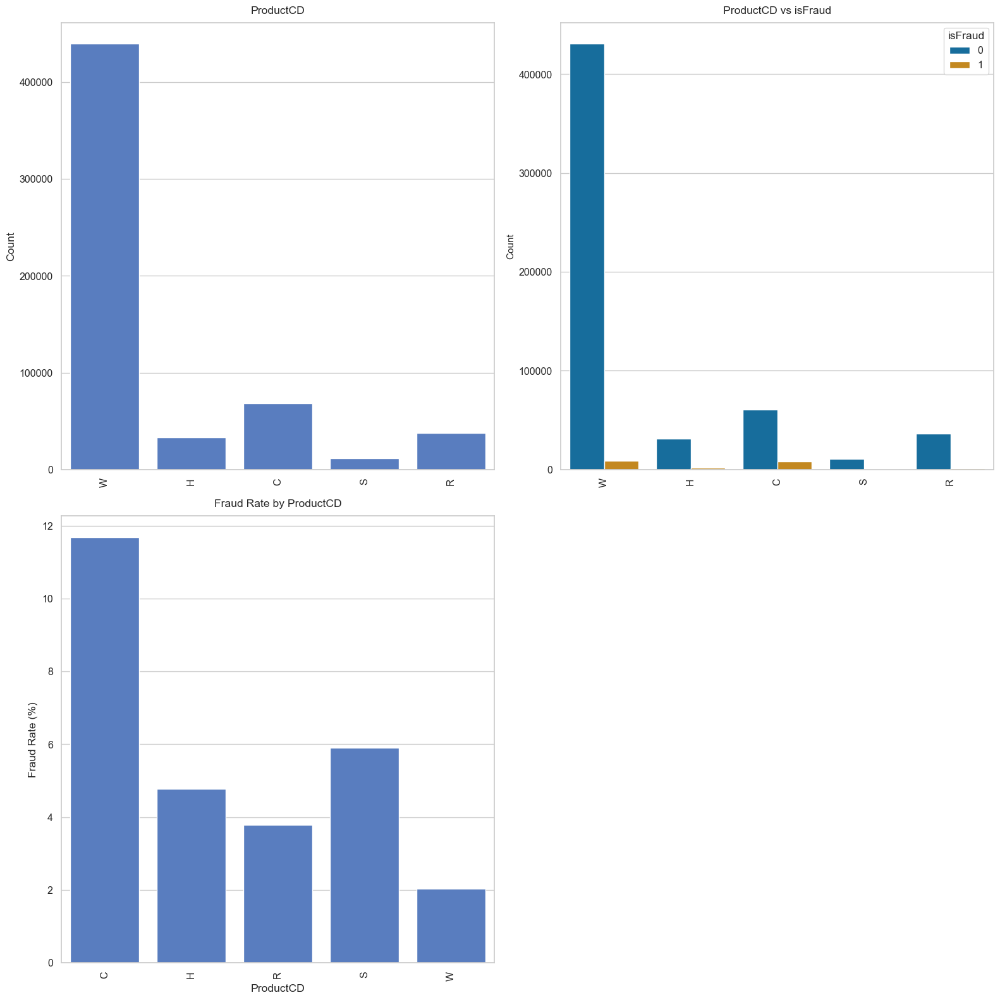

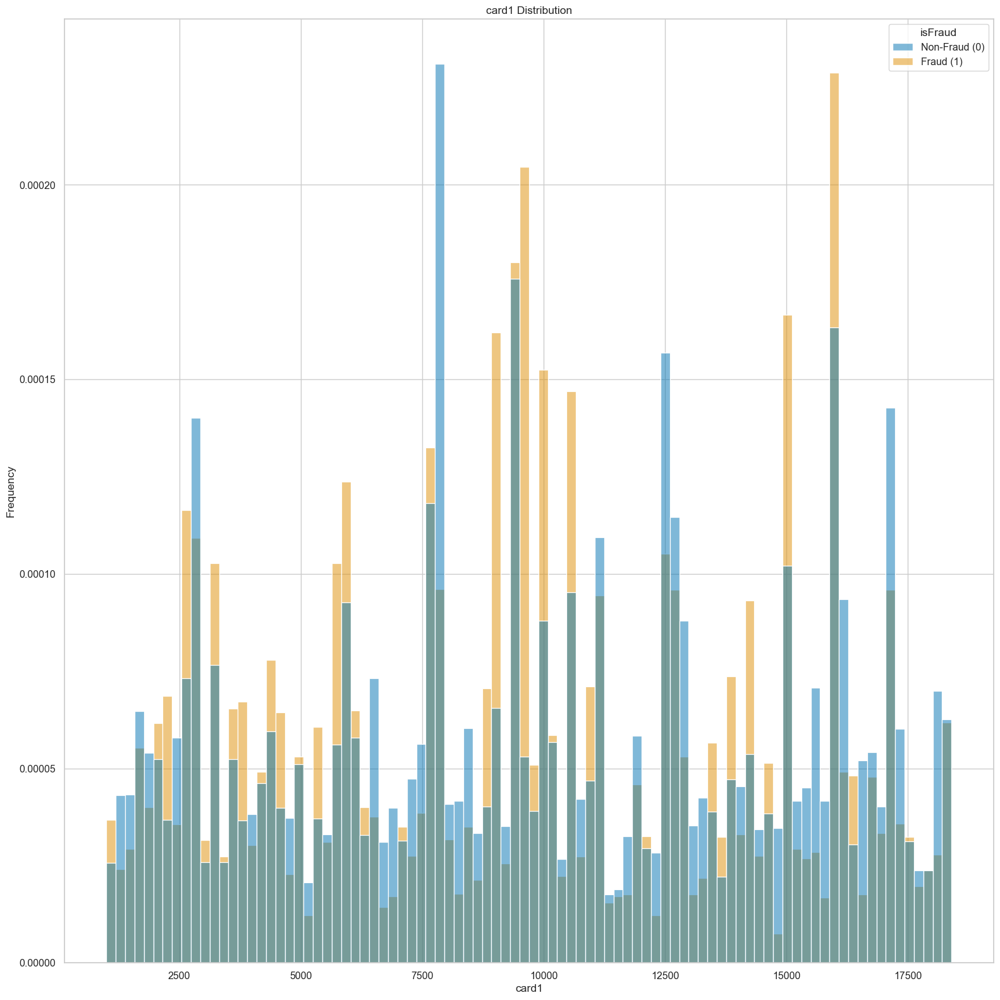

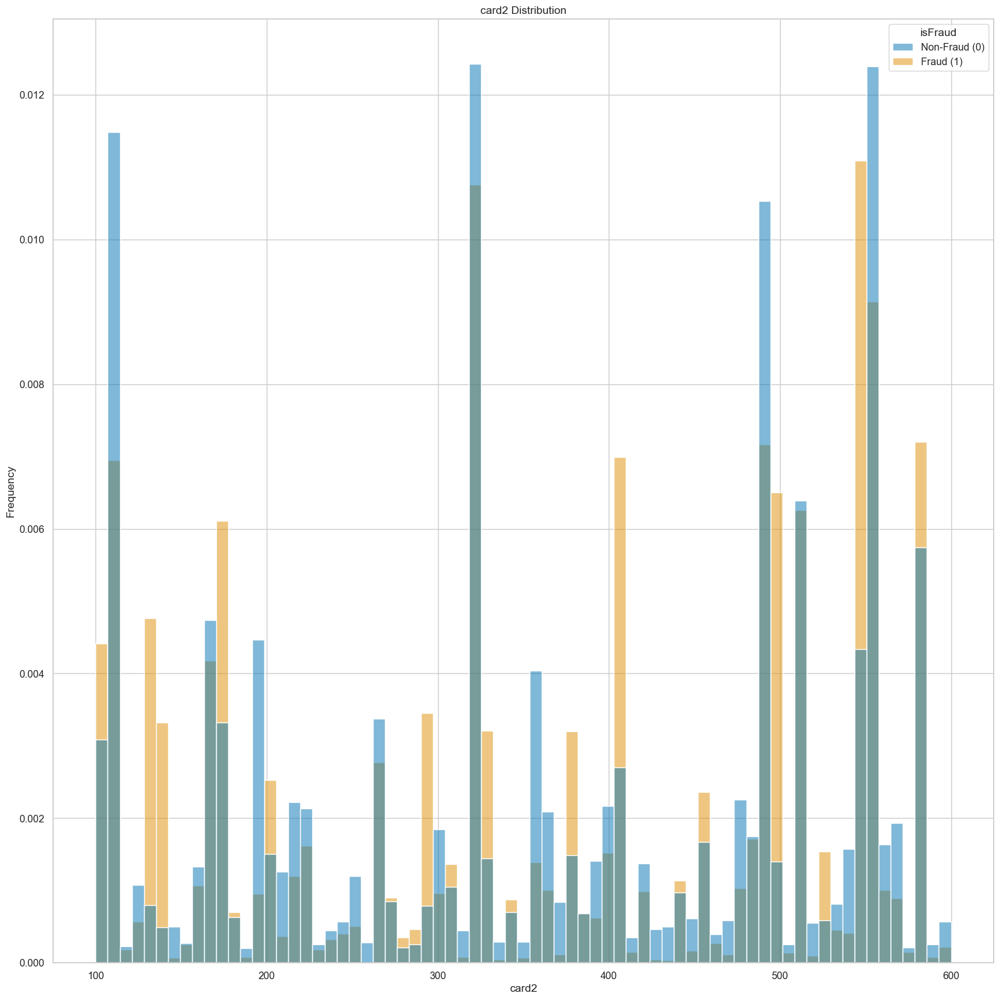

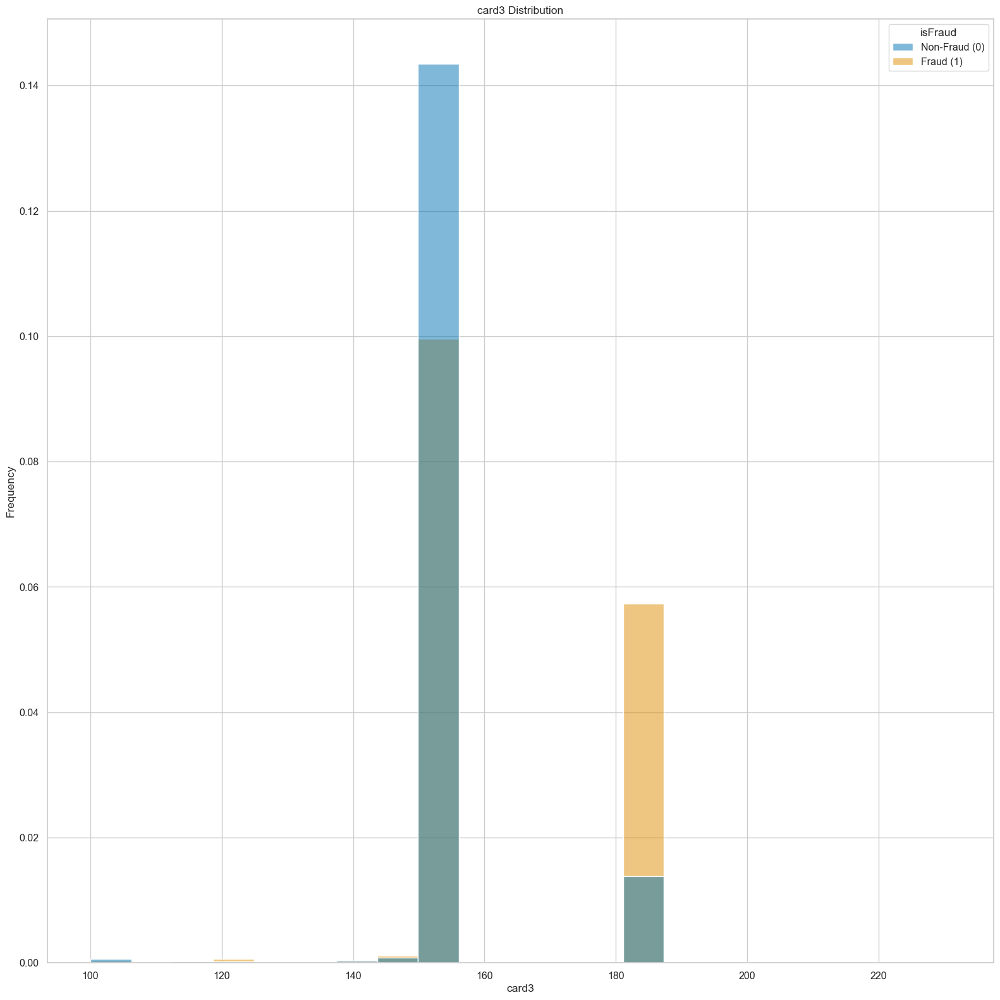

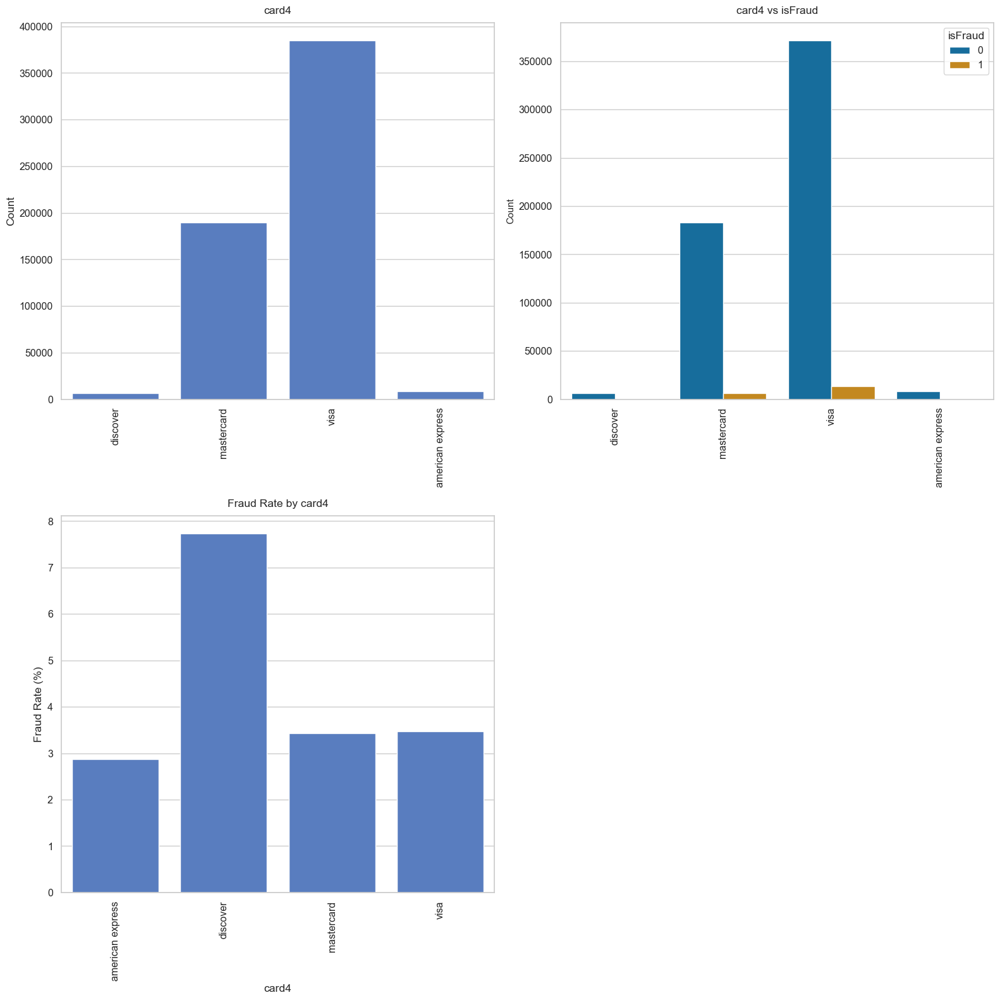

...

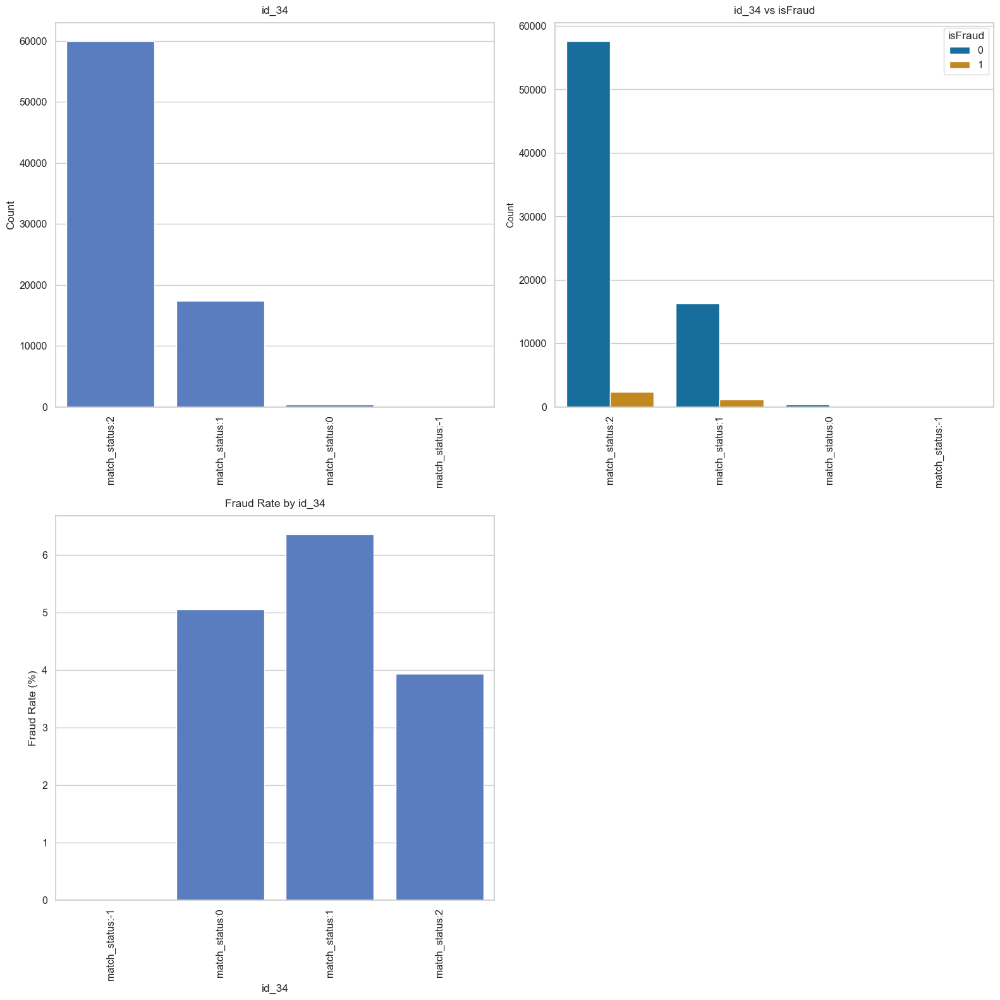

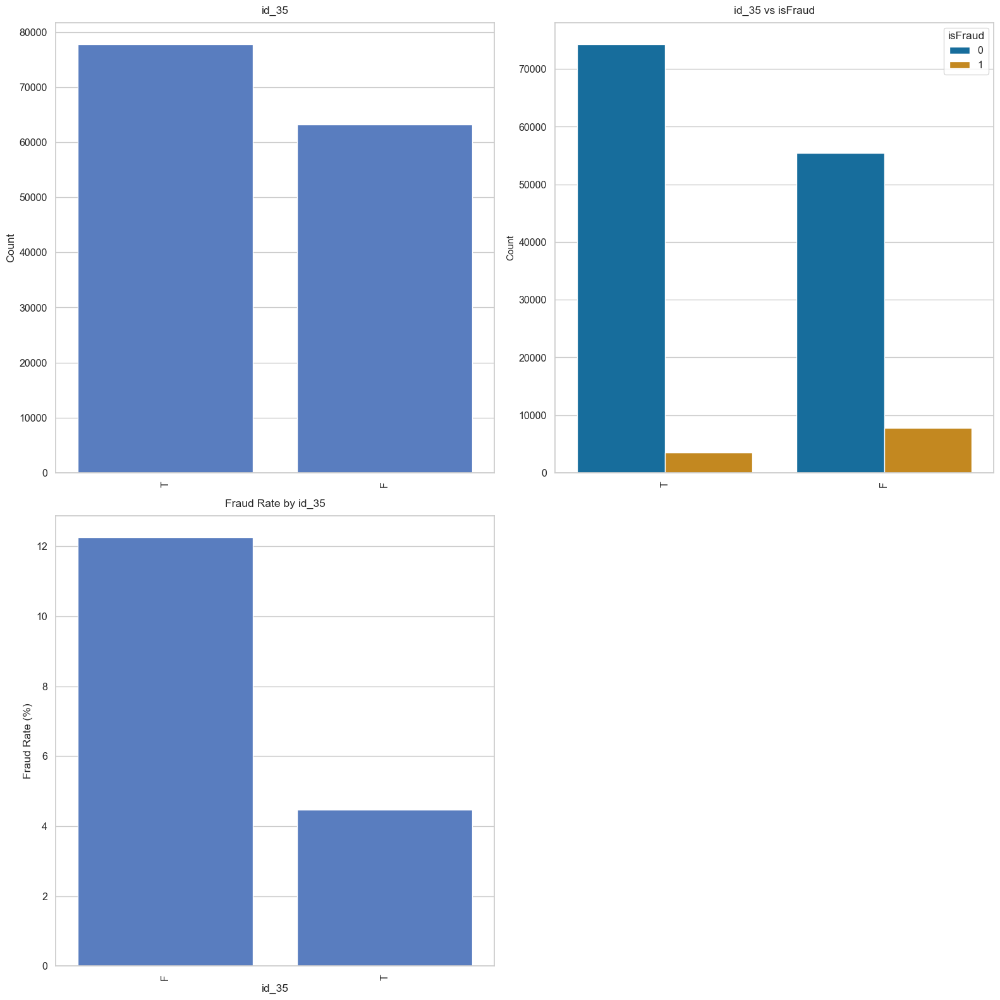

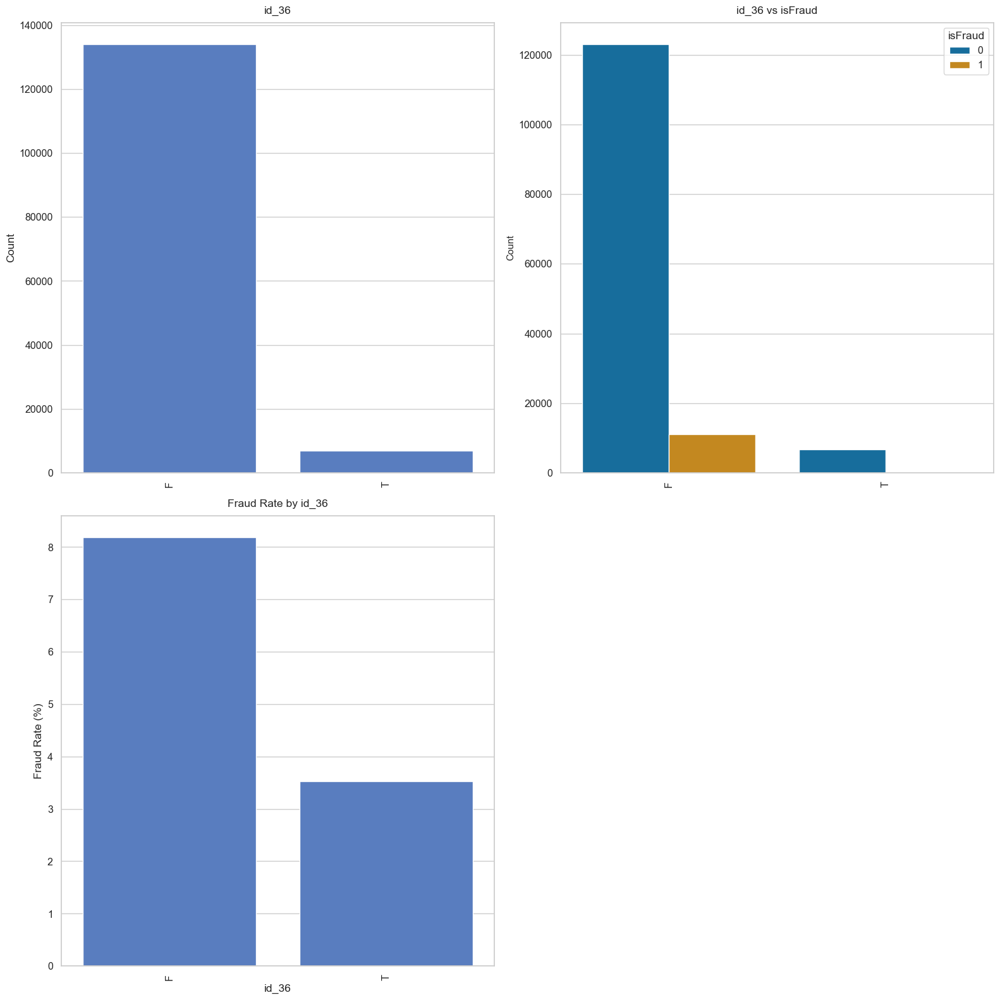

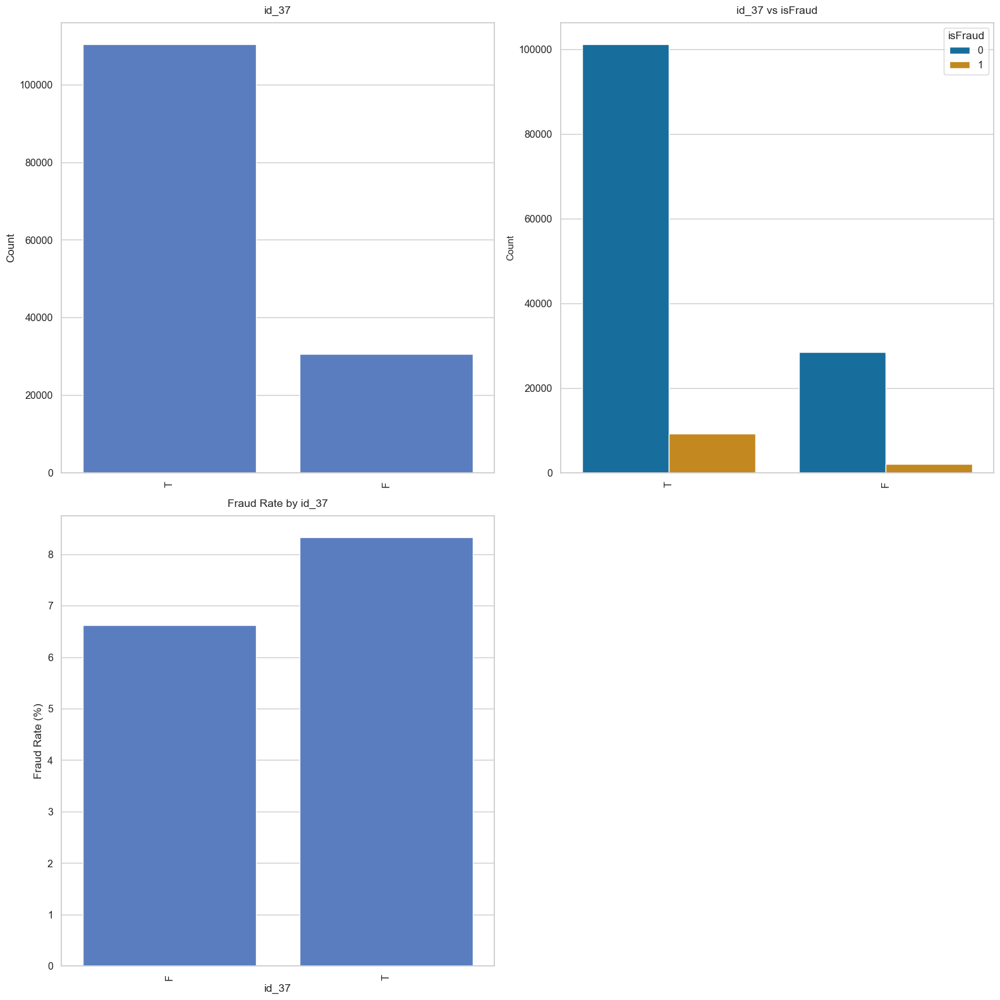

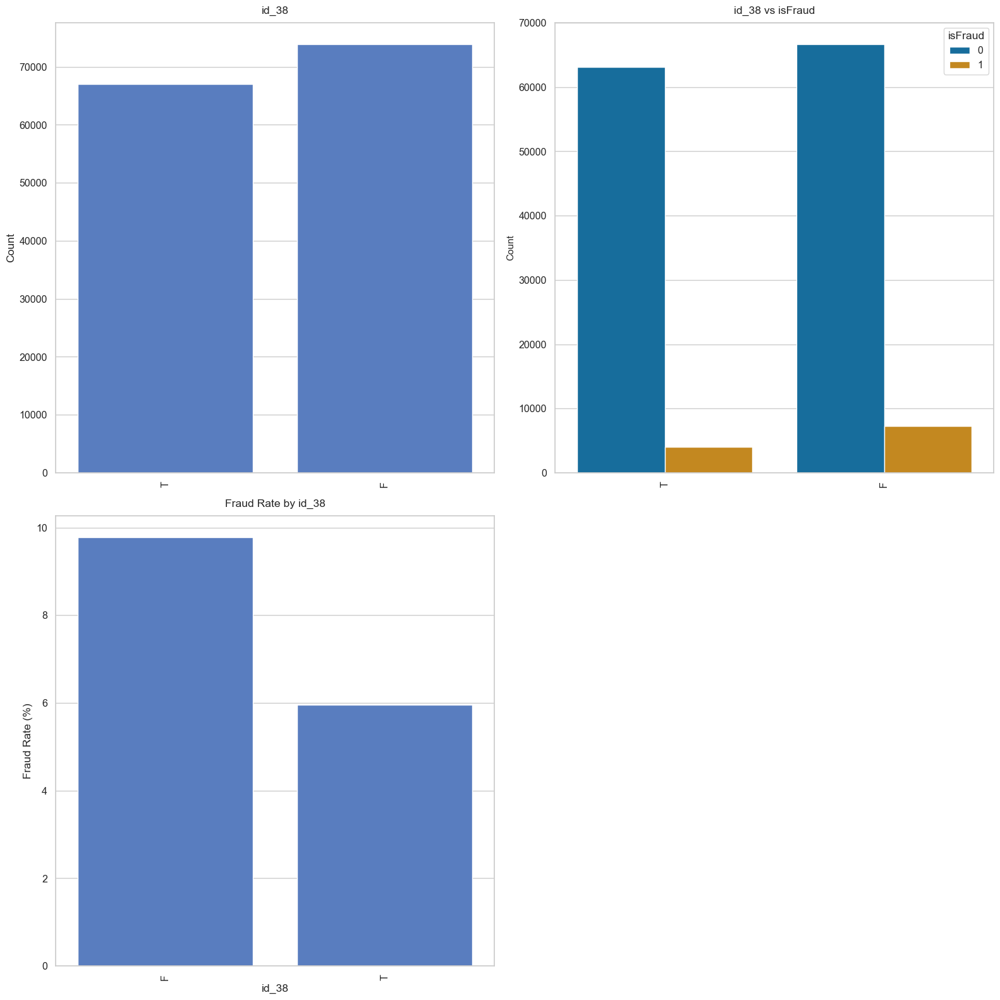

In [14]:
# Unique Count
categorical_cols = [
    "ProductCD", "card1", "card2", "card3", "card4", "card5", "card6", "addr1", "addr2", 
    "P_emaildomain", "R_emaildomain", "M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9",
    "DeviceType", "DeviceInfo"
] + [col for col in df.columns if ((col.startswith("id_")) and (int(col[-2:]) >= 12))]

for categorical_col in categorical_cols:
    if sorted_profile.at[categorical_col, "dtype"] == "object":
        fig = plt.figure(figsize=(16, 16))
        fig.subplots_adjust(hspace = 0.5, wspace = 0.5)
        
        # Plot Count Plot
        plt.subplot(2, 2, 1)
        sns.countplot(x=categorical_col, data=df, color="#4878D0")
        plt.title(categorical_col, pad=10)
        plt.ylabel("Count")
        plt.tick_params(axis='x', labelrotation=90)
        plt.xlabel("")

        # Plot countplot with binary target hue
        plt.subplot(2, 2, 2)
        sns.countplot(
            x=categorical_col, 
            hue=LABEL_COL, 
            data=df
        )
        plt.title(f"{categorical_col} vs {LABEL_COL}", pad=10)
        plt.tick_params(axis='x', labelrotation=90)
        plt.xlabel("")
        plt.ylabel("Count", fontsize=11)

        # Plot proportion of fraud for each category type
        fraud_rate = df.groupby(categorical_col)[LABEL_COL].mean().reset_index(name='Fraud Rate')
        fraud_rate['Fraud Rate'] = fraud_rate['Fraud Rate'] * 100
        plt.subplot(2, 2, 3)
        sns.barplot(data=fraud_rate, x=categorical_col, y='Fraud Rate', color="#4878D0")
        plt.title(f"Fraud Rate by {categorical_col}", pad=10)
        plt.tick_params(axis='x', labelrotation=90)
        plt.ylabel("Fraud Rate (%)")

        plt.tight_layout()
        plt.show()
    else:
        temp_hue = df[LABEL_COL].map({0: "Non-Fraud (0)", 1: "Fraud (1)"})
        plt.figure(figsize=(16, 16))
        sns.histplot(x=df[categorical_col], hue=temp_hue, stat="density", common_norm=False, legend=True)
        plt.title(f"{categorical_col} Distribution")
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

### 4.2.2 Numerical Variables

#### Transaction Amount

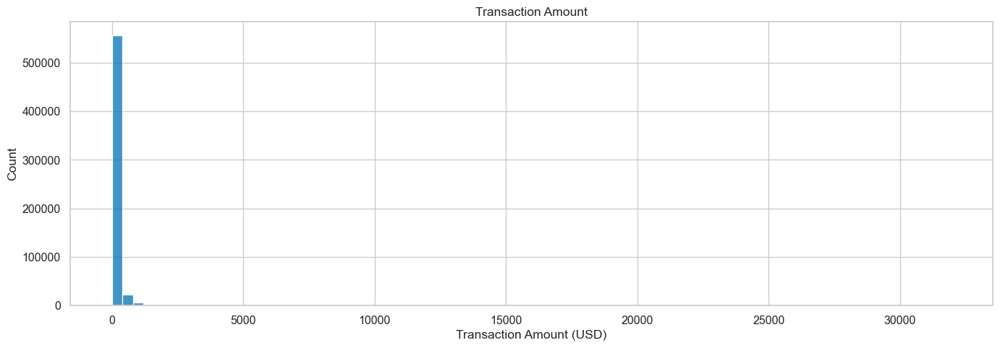

In [15]:
# Original Unmodified Transaction Amount
fig, ax = plt.subplots(figsize=(14, 5))

sns.histplot(data=df, x="TransactionAmt", bins=80)
ax.set_title("Transaction Amount")
ax.set_xlabel("Transaction Amount (USD)")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

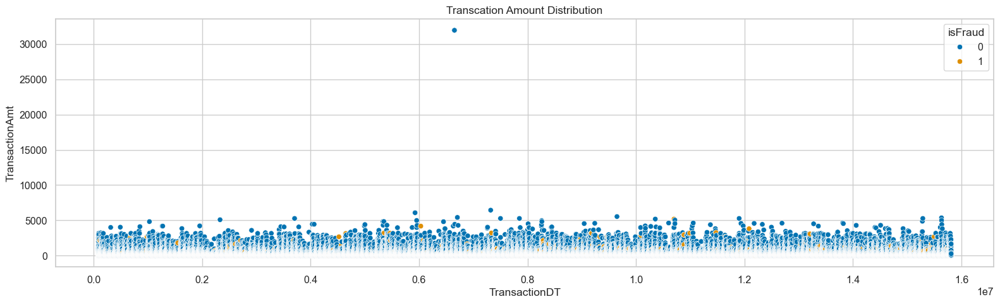

In [16]:
# Check for Outliers 
fig = plt.subplots(figsize=(16, 5))

sns.scatterplot(y=df['TransactionAmt'],x=df['TransactionDT'],hue=df['isFraud'])
plt.title('Transcation Amount Distribution')
plt.tight_layout()
plt.show()

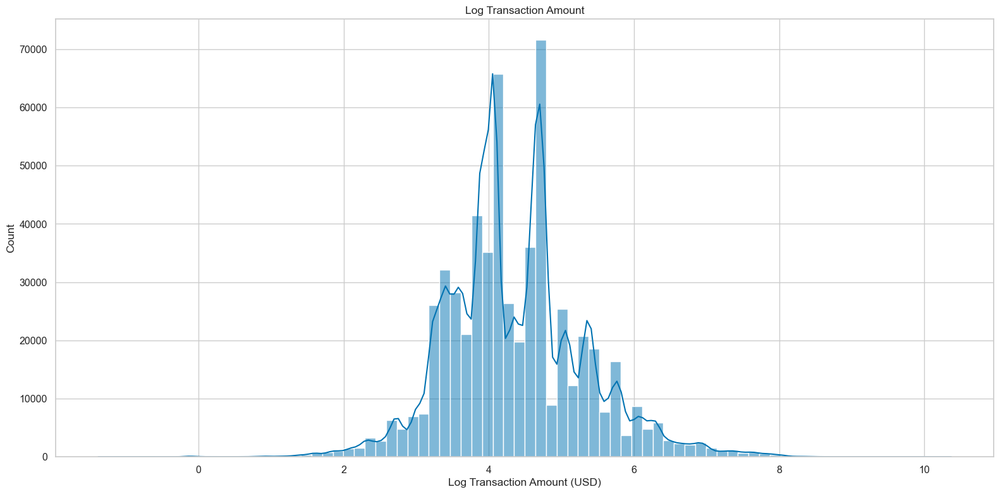

In [17]:
# Natural Log Transform TransactionAmt
fig, ax = plt.subplots(figsize=(16, 8))

sns.histplot(data=df, x=np.log(df["TransactionAmt"]), bins=80, kde=True)
ax.set_title("Log Transaction Amount")
ax.set_xlabel("Log Transaction Amount (USD)")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

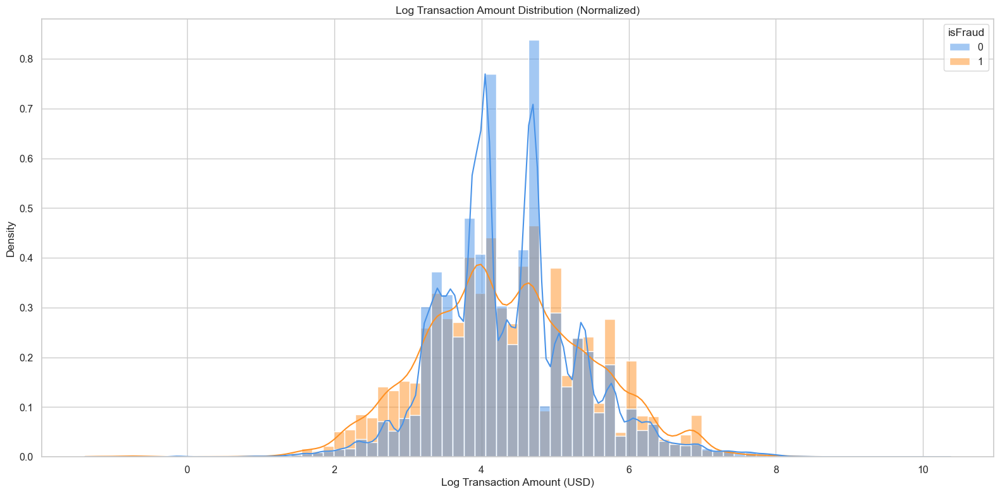

In [18]:
# Natural Log Transform TransactionAmt by isFraud
fig, ax = plt.subplots(figsize=(16, 8))

sns.histplot(
    data=df,
    x=np.log(df["TransactionAmt"]),
    bins=80,
    hue=df[LABEL_COL],
    kde=True,
    palette=["#4993E8", "#FF9123"],
    stat="density",  # Normalizes counts to density
    common_norm=False  # Normalizes each hue group independently
)

ax.set_title("Log Transaction Amount Distribution (Normalized)")
ax.set_xlabel("Log Transaction Amount (USD)")
ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

In [19]:
df["Log_TransactionAmt"] = np.log(df["TransactionAmt"])

In [20]:
# Create a copy for box plots
plot_df = df.copy()
plot_fraud_df = plot_df[plot_df[LABEL_COL] == 1]
plot_not_fraud_df = plot_df[plot_df[LABEL_COL] == 0]

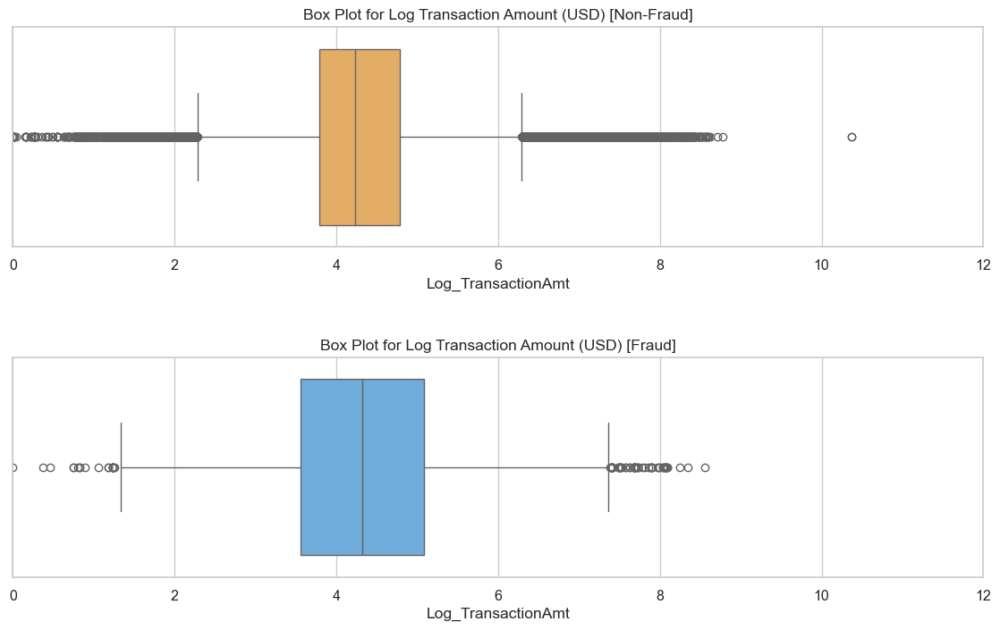

In [21]:
# Box Plot of Log TransactionAmt and isFraud
fig, axes = plt.subplots(nrows=2, ncols=1,figsize=(14,8))
fig.subplots_adjust(hspace = 0.5, wspace = 0.5)

sns.boxplot(x=plot_not_fraud_df['Log_TransactionAmt'],ax=axes[0], color="#F9B051")
axes[0].title.set_text('Box Plot for Log Transaction Amount (USD) [Non-Fraud]')
axes[0].set(xlim=(0, 12))

sns.boxplot(x=plot_fraud_df['Log_TransactionAmt'],ax=axes[1],color="#5FAEEA")
axes[1].title.set_text('Box Plot for Log Transaction Amount (USD) [Fraud]')
axes[1].set(xlim=(0, 12))
plt.show()

In [22]:
# Quantile Statistics for Log_TransactionAmt
quantile = plot_not_fraud_df["Log_TransactionAmt"].describe().loc[['min', '25%', '50%', '75%', 'max']]
print("Quantile Statistics for Log Transaction For Non-Fraudulent Transactions")
print(quantile)

quantile_fraud = plot_fraud_df["Log_TransactionAmt"].describe().loc[['min', '25%', '50%', '75%', 'max']]
print("\nQuantile Statistics for Log Transaction For Fraudulent Transactions")
print(quantile_fraud)

Quantile Statistics for Log Transaction For Non-Fraudulent Transactions
min   -1.38
25%    3.78
50%    4.23
75%    4.79
max   10.37
Name: Log_TransactionAmt, dtype: float64

Quantile Statistics for Log Transaction For Fraudulent Transactions
min   -1.23
25%    3.56
50%    4.32
75%    5.08
max    8.55
Name: Log_TransactionAmt, dtype: float64


#### Dist1 and Dist2

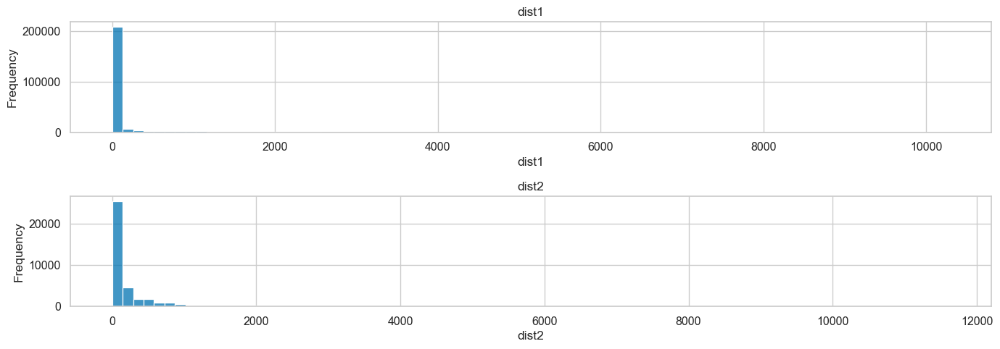

In [23]:
# Original Unmodified Dist1 and Dist2
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(data=df, x="dist1", bins=80, ax=axes[0])
axes[0].set_title("dist1")
axes[0].set_xlabel("dist1")
axes[0].set_ylabel("Frequency")

sns.histplot(data=df, x="dist2", bins=80, ax=axes[1])
axes[1].set_title("dist2")
axes[1].set_xlabel("dist2")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

c:\My Data\Year 4 Sem 1\BT4012\BT4012 Group Project\BT4012 Project Code\.venv\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\My Data\Year 4 Sem 1\BT4012\BT4012 Group Project\BT4012 Project Code\.venv\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


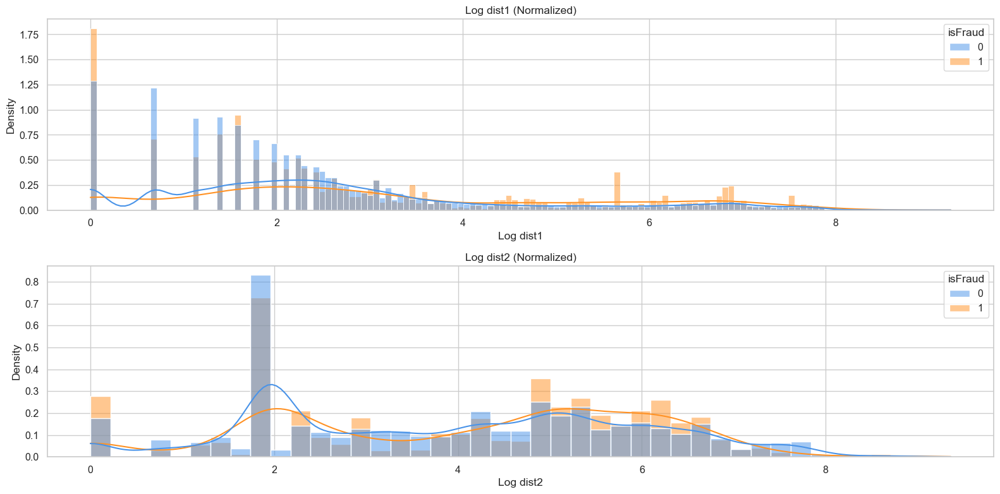

In [24]:
# Natural Log Transform TransactionAmt by isFraud
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

sns.histplot(
    data=df,
    x=np.log(df["dist1"]),
    # bins=5000,
    hue=df[LABEL_COL],
    kde=True,
    ax=axes[0],
    palette=["#4993E8", "#FF9123"],
    stat="density",  # Normalizes counts to density
    common_norm=False  # Normalizes each hue group independently
)

axes[0].set_title("Log dist1 (Normalized)")
axes[0].set_xlabel("Log dist1")
axes[0].set_ylabel("Density")

sns.histplot(
    data=df,
    x=np.log(df["dist2"]),
    # bins=5000,
    hue=df[LABEL_COL],
    kde=True,
    ax=axes[1],
    palette=["#4993E8", "#FF9123"],
    stat="density",  # Normalizes counts to density
    common_norm=False  # Normalizes each hue group independently
)

axes[1].set_title("Log dist2 (Normalized)")
axes[1].set_xlabel("Log dist2")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()

In [25]:
df["Log_dist1"] = np.log(df["dist1"])
df["Log_dist2"] = np.log(df["dist2"])

# Create a copy for box plots
plot_df = df.copy()
plot_fraud_df = plot_df[plot_df[LABEL_COL] == 1]
plot_not_fraud_df = plot_df[plot_df[LABEL_COL] == 0]

c:\My Data\Year 4 Sem 1\BT4012\BT4012 Group Project\BT4012 Project Code\.venv\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\My Data\Year 4 Sem 1\BT4012\BT4012 Group Project\BT4012 Project Code\.venv\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


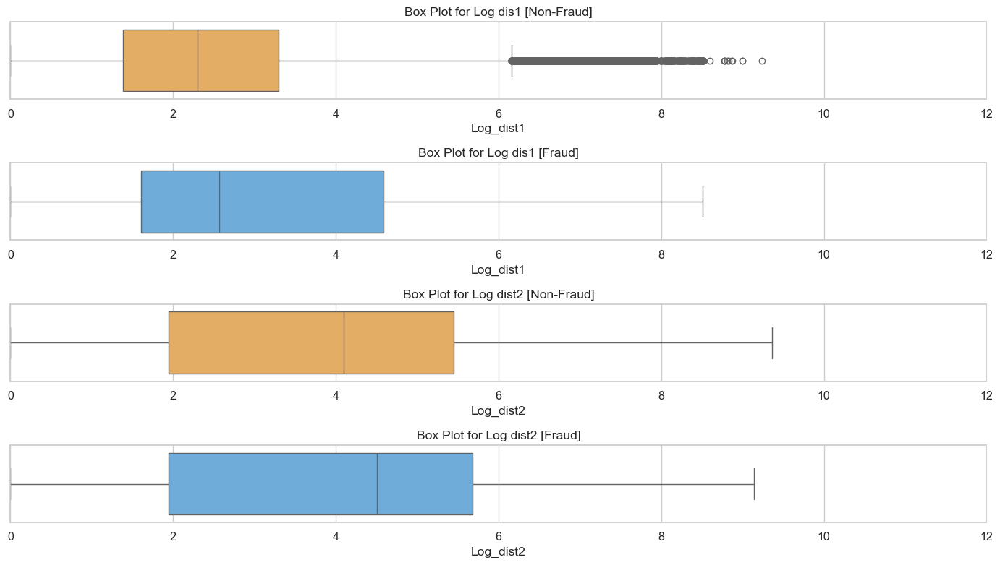

In [26]:
# Box Plot of Log dis1 and dist2 and isFraud
fig, axes = plt.subplots(nrows=4, ncols=1,figsize=(14,8))
fig.subplots_adjust(hspace = 0.5, wspace = 0.5)

sns.boxplot(x=plot_not_fraud_df['Log_dist1'],ax=axes[0], color="#F9B051")
axes[0].title.set_text('Box Plot for Log dis1 [Non-Fraud]')
axes[0].set(xlim=(0, 12))

sns.boxplot(x=plot_fraud_df['Log_dist1'],ax=axes[1],color="#5FAEEA")
axes[1].title.set_text('Box Plot for Log dis1 [Fraud]')
axes[1].set(xlim=(0, 12))

sns.boxplot(x=plot_not_fraud_df['Log_dist2'],ax=axes[2], color="#F9B051")
axes[2].title.set_text('Box Plot for Log dist2 [Non-Fraud]')
axes[2].set(xlim=(0, 12))

sns.boxplot(x=plot_fraud_df['Log_dist2'],ax=axes[3],color="#5FAEEA")
axes[3].title.set_text('Box Plot for Log dist2 [Fraud]')
axes[3].set(xlim=(0, 12))
plt.tight_layout()
plt.show()

#### Quantile Statistics

In [27]:
numerical_cols = []

for col in df.columns:
    if (col not in categorical_cols) and (col != LABEL_COL) and (col != TIME_COL) and (col != ID_COL):
        numerical_cols.append(col)

quantile = df[numerical_cols].describe().loc[['min', '25%', '50%', '75%', 'max']].transpose()
quantile.columns = ['min', 'Q1', 'Q2', 'Q3', 'max']
quantile['range'] = quantile['max'] - quantile['min']
quantile['IQR'] = quantile['Q3'] - quantile['Q1']
quantile.head()

c:\My Data\Year 4 Sem 1\BT4012\BT4012 Group Project\BT4012 Project Code\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\My Data\Year 4 Sem 1\BT4012\BT4012 Group Project\BT4012 Project Code\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,min,Q1,Q2,Q3,max,range,IQR
TransactionAmt,0.25,43.32,68.77,125.00,"31,937.39","31,937.14",81.68
dist1,0.00,3.00,8.00,24.00,"10,286.00","10,286.00",21.00
dist2,0.00,7.00,37.00,206.00,"11,623.00","11,623.00",199.00
C1,0.00,1.00,1.00,3.00,"4,685.00","4,685.00",2.00
C2,0.00,1.00,1.00,3.00,"5,691.00","5,691.00",2.00


If we use the unmodified TransactionAmt, we can consider removing the outlier.

### 4.2.3 Time Series Analysis Using TransactionDT

From the discussion forum on Kaggle regarding this dataset:

TransactionDT: timedelta from a given reference datetime (not an actual timestamp) “TransactionDT first value is 86400, which corresponds to the number of seconds in a day (60 * 60 * 24 = 86400) so I think the unit is seconds. Using this, we know the data spans 6 months, as the maximum value is 15811131, which would correspond to day 183.”

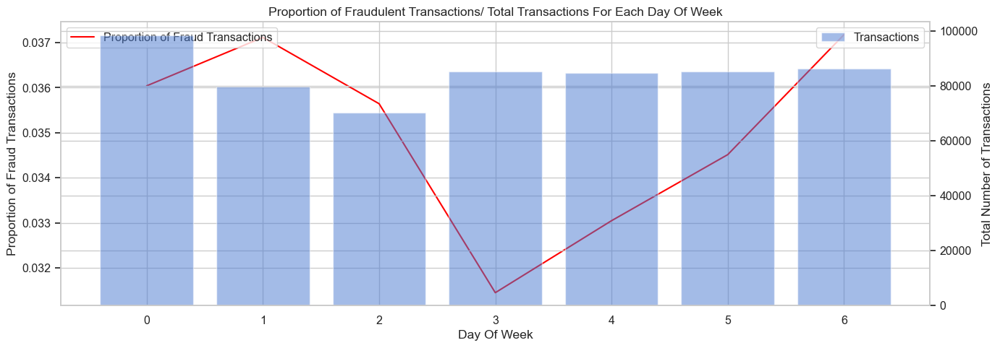

In [28]:
df["Day_Of_Week"] = (df[TIME_COL]//(60*60*24)-1)%7

temp_fraud = df.groupby("Day_Of_Week")[LABEL_COL].mean().reset_index()
temp_fraud = temp_fraud.rename(columns={LABEL_COL: "Proportion of Fraud Transactions"})

temp_transactions = df.groupby("Day_Of_Week")[ID_COL].count().reset_index()
temp_transactions = temp_transactions.rename(columns={ID_COL: "Total Number of Transactions"})

temp_fraud_transactions = temp_fraud.merge(temp_transactions, on="Day_Of_Week", how="left")

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(temp_fraud_transactions["Day_Of_Week"], temp_fraud_transactions["Proportion of Fraud Transactions"], label="Proportion of Fraud Transactions", color="red")
ax1.set_ylabel("Proportion of Fraud Transactions")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.bar(temp_fraud_transactions["Day_Of_Week"], temp_fraud_transactions["Total Number of Transactions"], color="#4878D0", alpha=0.50, label="Transactions")
ax2.set_ylabel("Total Number of Transactions")
ax2.legend(loc="upper right")

ax1.set_title("Proportion of Fraudulent Transactions/ Total Transactions For Each Day Of Week")
ax1.set_xlabel("Day Of Week")
plt.tight_layout()
plt.show()

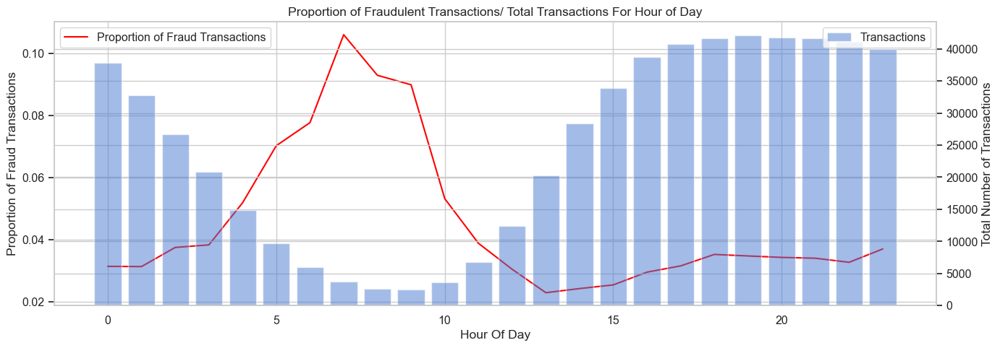

In [29]:
df["Hour_Of_Day"] = (df[TIME_COL]//(60*60))%24

temp_hour_fraud = df.groupby("Hour_Of_Day")[LABEL_COL].mean().reset_index()
temp_hour_fraud = temp_hour_fraud.rename(columns={LABEL_COL: "Proportion of Fraud Transactions"})

temp_transactions = df.groupby("Hour_Of_Day")[ID_COL].count().reset_index()
temp_transactions = temp_transactions.rename(columns={ID_COL: "Total Number of Transactions"})

temp_hour_fraud_transactions = temp_hour_fraud.merge(temp_transactions, on="Hour_Of_Day", how="left")

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(temp_hour_fraud_transactions["Hour_Of_Day"], temp_hour_fraud_transactions["Proportion of Fraud Transactions"], label="Proportion of Fraud Transactions", color="#FF0000")
ax1.set_ylabel("Proportion of Fraud Transactions")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.bar(temp_hour_fraud_transactions["Hour_Of_Day"], temp_hour_fraud_transactions["Total Number of Transactions"], color="#4878D0", alpha=0.50, label="Transactions")
ax2.set_ylabel("Total Number of Transactions")
ax2.legend(loc="upper right")

ax1.set_title("Proportion of Fraudulent Transactions/ Total Transactions For Hour of Day")
ax1.set_xlabel("Hour Of Day")
plt.tight_layout()
plt.show()

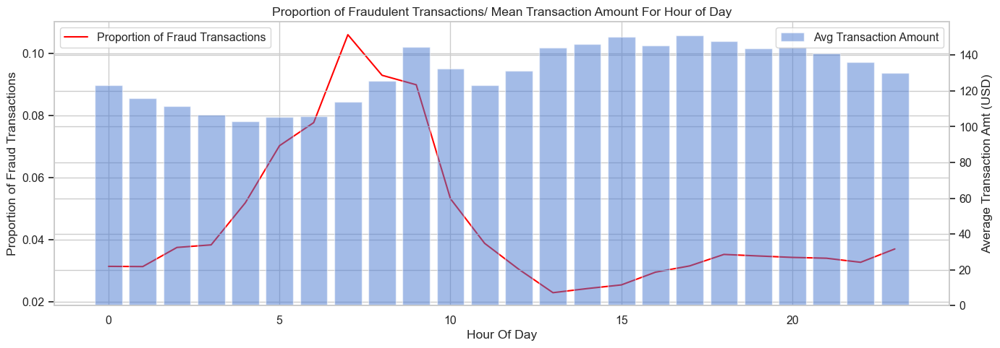

In [30]:
df["Hour_Of_Day"] = (df[TIME_COL]//(60*60))%24

temp_hour_fraud = df.groupby("Hour_Of_Day")[LABEL_COL].mean().reset_index()
temp_hour_fraud = temp_hour_fraud.rename(columns={LABEL_COL: "Proportion of Fraud Transactions"})

temp_transactions = df.groupby("Hour_Of_Day")["TransactionAmt"].mean().reset_index()
temp_transactions = temp_transactions.rename(columns={"TransactionAmt": "Average Transaction Amt (USD)"})

temp_hour_fraud_transactions = temp_hour_fraud.merge(temp_transactions, on="Hour_Of_Day", how="left")

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(temp_hour_fraud_transactions["Hour_Of_Day"], temp_hour_fraud_transactions["Proportion of Fraud Transactions"], label="Proportion of Fraud Transactions", color="#FF0000")
ax1.set_ylabel("Proportion of Fraud Transactions")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.bar(temp_hour_fraud_transactions["Hour_Of_Day"], temp_hour_fraud_transactions["Average Transaction Amt (USD)"], color="#4878D0", alpha=0.50, label="Avg Transaction Amount")
ax2.set_ylabel("Average Transaction Amt (USD)")
ax2.legend(loc="upper right")

ax1.set_title("Proportion of Fraudulent Transactions/ Mean Transaction Amount For Hour of Day")
ax1.set_xlabel("Hour Of Day")
plt.tight_layout()
plt.show()

## 4.3 Correlation Analysis

In [31]:
# Sample 500 fraud and 500 non-fraud examples to plot
sample_df = pd.concat([df.loc[df[LABEL_COL] == 0].sample(500),
                       df.loc[df[LABEL_COL] == 1].sample(500)])

### `C1` - `C14`

<Figure size 2500x2500 with 0 Axes>

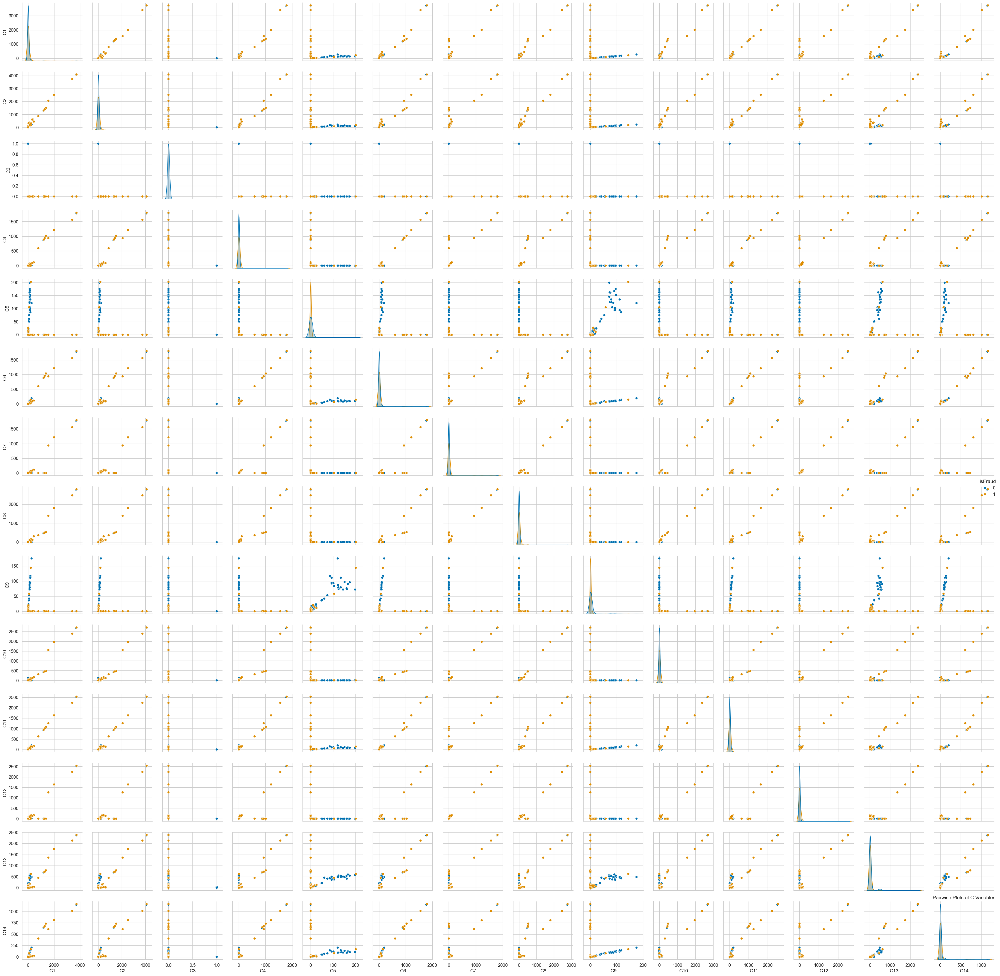

In [32]:
c_cols = [col for col in df.columns if col.startswith("C")]

plt.figure(figsize=(25,25))
sns.pairplot(
    sample_df, 
    vars=c_cols,
    hue=LABEL_COL,
    diag_kind="kde"
)
plt.title('Pairwise Plots of C Variables')
plt.tight_layout()
plt.show()

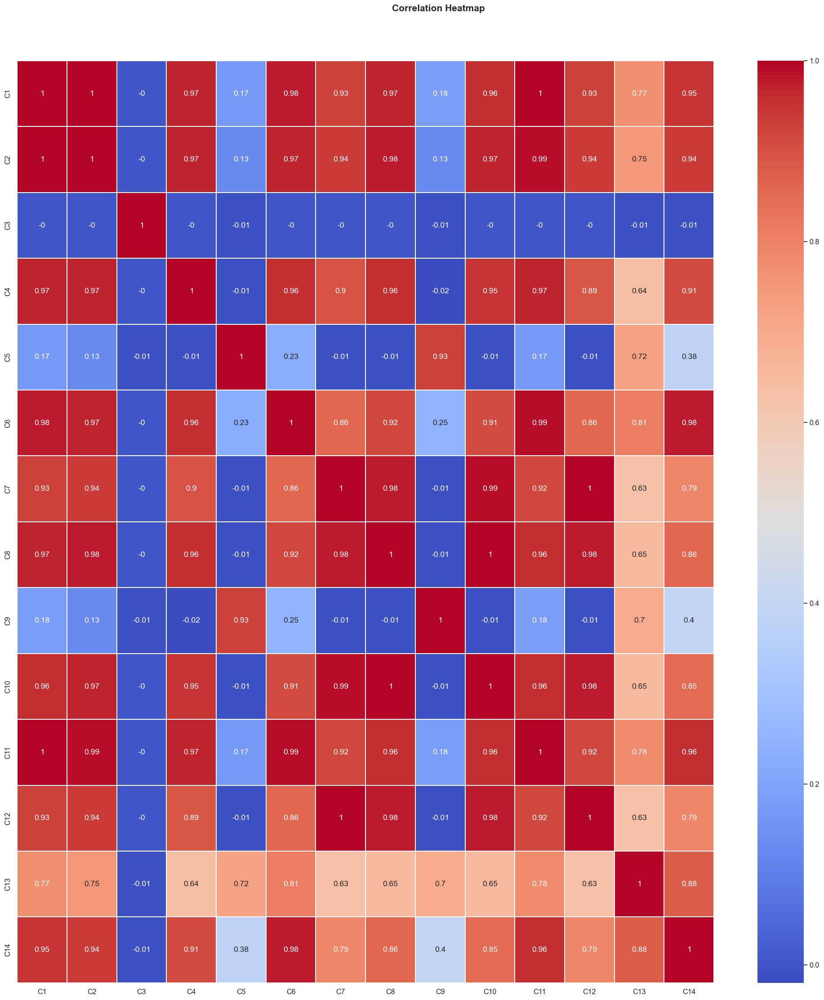

In [33]:
# Correlation Heat Map
# Pearson correlation coefficients between all pairs of numerical variables
fig, ax = plt.subplots(1,1, figsize=(25,25))

hm = sns.heatmap(round(df[c_cols].corr(),2),
                 ax=ax,
                 cmap="coolwarm",
                 annot=True,
                 linewidths=.05)

fig.subplots_adjust(top=0.93)

t = fig.suptitle('Correlation Heatmap', fontweight='bold')

In [34]:
c_cols_missing_vals_df = profile.loc[c_cols]
c_cols_missing_vals_df

,dtype,non_null,null_%,n_unique,sample_value
C1,float64,590540,0.00,1657,1.00
C2,float64,590540,0.00,1216,1.00
C3,float64,590540,0.00,27,0.00
C4,float64,590540,0.00,1260,0.00
C5,float64,590540,0.00,319,0.00
C6,float64,590540,0.00,1328,1.00
C7,float64,590540,0.00,1103,0.00
C8,float64,590540,0.00,1253,0.00
C9,float64,590540,0.00,205,1.00
C10,float64,590540,0.00,1231,0.00


### `D1` - `D15`

<Figure size 2500x2500 with 0 Axes>

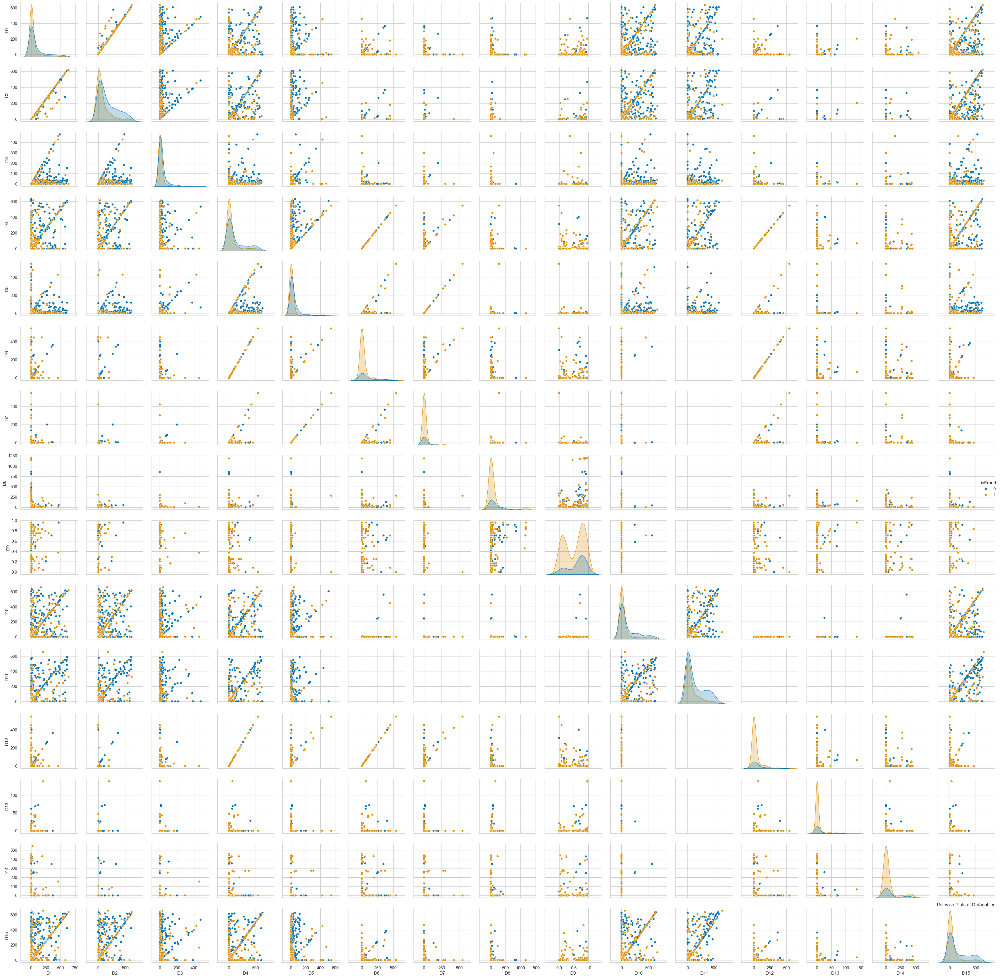

In [35]:
d_cols = [col for col in df.columns if (col.startswith("D")) and (len(col) <=3)]

plt.figure(figsize=(25,25))
sns.pairplot(
    sample_df, 
    vars=d_cols,
    hue=LABEL_COL,
    diag_kind="kde"
)
plt.title('Pairwise Plots of D Variables')
plt.tight_layout()
plt.show()

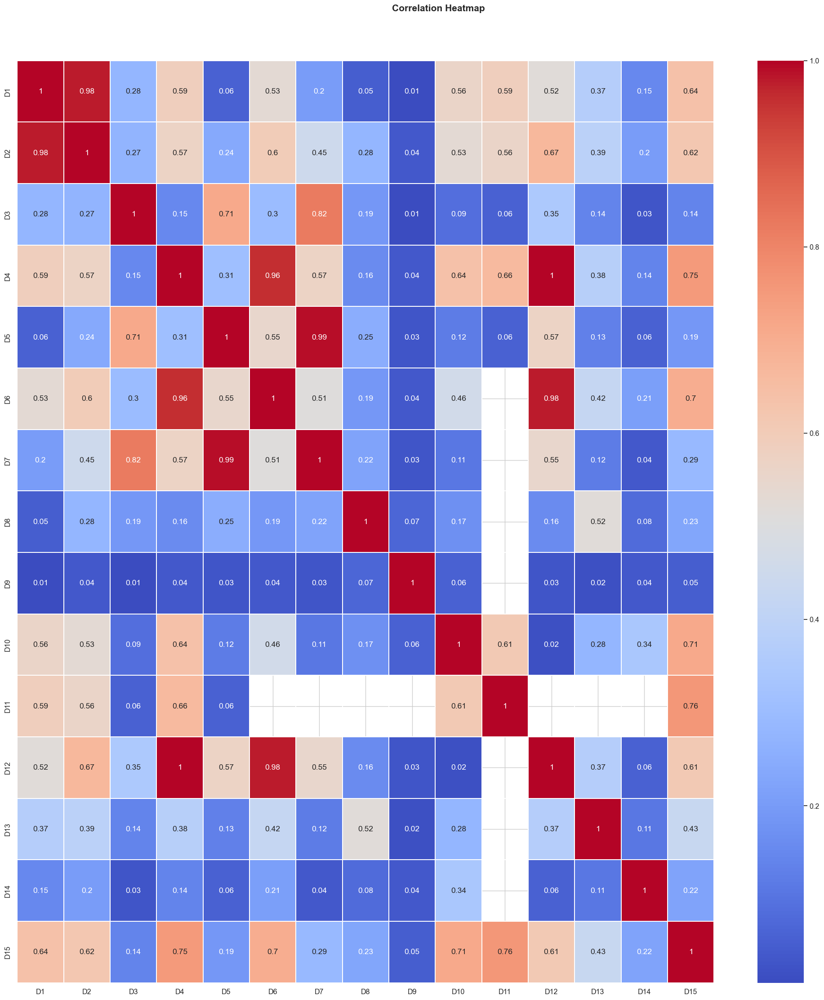

In [36]:
# Correlation Heat Map
# Pearson correlation coefficients between all pairs of numerical variables
fig, ax = plt.subplots(1,1, figsize=(25,25))

hm = sns.heatmap(round(df[d_cols].corr(),2),
                 ax=ax,
                 cmap="coolwarm",
                 annot=True,
                 linewidths=.05)

fig.subplots_adjust(top=0.93)

t = fig.suptitle('Correlation Heatmap', fontweight='bold')

In [37]:
d_cols_missing_vals_df = profile.loc[d_cols]
d_cols_missing_vals_df

,dtype,non_null,null_%,n_unique,sample_value
D1,float64,589271,0.21,641,14.00
D2,float64,309743,47.55,641,NaN
D3,float64,327662,44.51,649,13.00
D4,float64,421618,28.60,808,NaN
D5,float64,280699,52.47,688,NaN
D6,float64,73187,87.61,829,NaN
D7,float64,38917,93.41,597,NaN
D8,float64,74926,87.31,12353,NaN
D9,float64,74926,87.31,24,NaN
D10,float64,514518,12.87,818,13.00


### `V1` - `V339`

Pairplot cell takes very long to run.

In [ ]:
# v_cols = [col for col in df.columns if (col.startswith("V")) and (len(col) <=4)]

# plt.figure(figsize=(35,35))
# sns.pairplot(
#     sample_df, 
#     vars=v_cols,
#     hue=LABEL_COL,
#     diag_kind="kde"
# )
# plt.title('Pairwise Plots of V Variables')
# plt.tight_layout()
# plt.show()

<Figure size 3500x3500 with 0 Axes>

In [38]:
v_cols = [col for col in df.columns if (col.startswith("V")) and (len(col) <=4)]

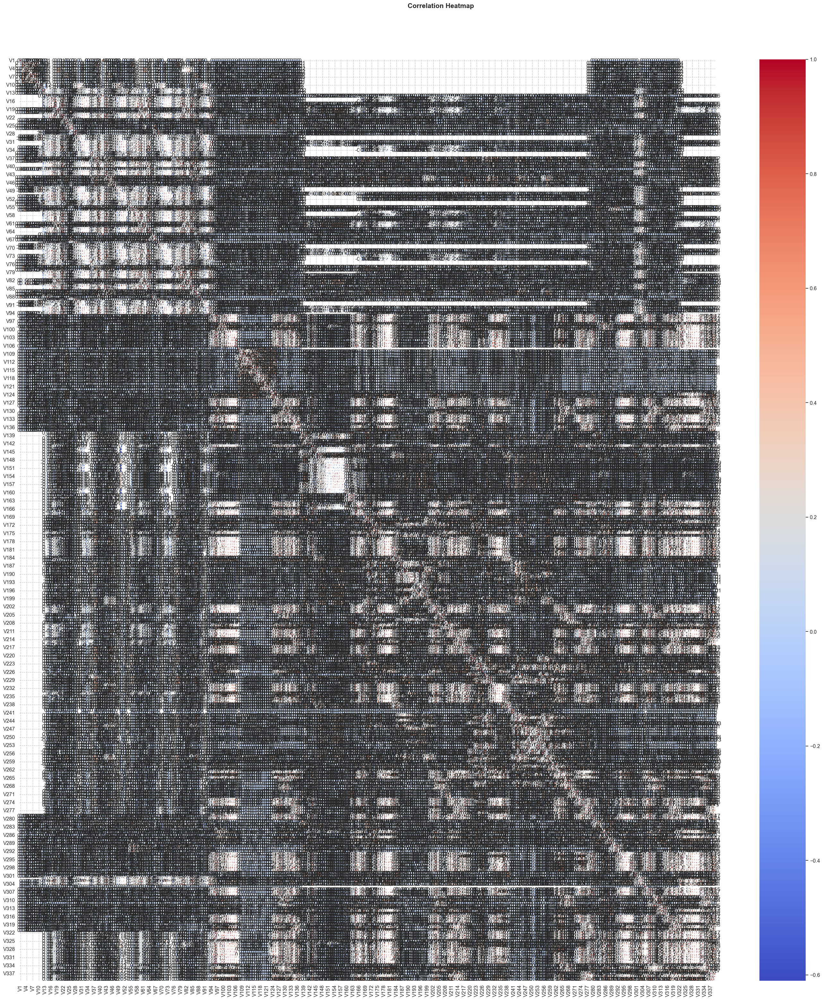

In [44]:
# Correlation Heat Map
# Pearson correlation coefficients between all pairs of numerical variables
fig, ax = plt.subplots(1,1, figsize=(35,35))

hm = sns.heatmap(round(df[v_cols].corr(),2),
                 ax=ax,
                 cmap="coolwarm",
                 annot=True,
                 linewidths=.05)

fig.subplots_adjust(top=0.93)

t = fig.suptitle('Correlation Heatmap', fontweight='bold')

In [39]:
v_cols_missing_vals_df = profile.loc[v_cols]
v_cols_missing_vals_df

,dtype,non_null,null_%,n_unique,sample_value
V1,float64,311253,47.29,2,1.00
V2,float64,311253,47.29,9,1.00
V3,float64,311253,47.29,10,1.00
V4,float64,311253,47.29,7,1.00
V5,float64,311253,47.29,7,1.00
V6,float64,311253,47.29,10,1.00
V7,float64,311253,47.29,10,1.00
V8,float64,311253,47.29,9,1.00
V9,float64,311253,47.29,9,1.00
V10,float64,311253,47.29,5,0.00


# 5. Feature Engineering

| Newly Engineered Column | Feature Type | Description |
| -------- | -------- | -------- |
| `Day_Of_Week` | Temporal | Return the day of week using `TransactionDT` |
| `Hour_Of_Day` | Temporal | Return the hour of the day using `TransactionDT` |
| `Transaction_Day` | Temporal | Return the day index using `TransactionDT`. Monotonically increasing, so it is used to build the UID / splits but is a poor model input for a forward-in-time split |
| `Log_TransactionAmt` | Numerical | Log Transformation of `TransactionAmt` |
| `Log_dist1` | Numerical | Log Transformation of `dist1`. Original `dist1` has some zero values, hence not all `Log_dist1` may be valid |
| `Log_dist2` | Numerical | Log Transformation of `dist2`. Original `dist2` has some zero values, hence not all `Log_dist2` may be valid |
| `P_email_company` | Categorical | Return the company that the `P_emaildomain` belongs to |
| `device_company` | Categorical | Return the device manufacturer / OS family parsed from `DeviceInfo` (`Unknown` when `DeviceInfo` is missing). Note that `DeviceInfo` itself is lower-cased and missing values are filled with `unknown_device` by this step |
| `TransactionDateTime` | Temporal (helper) | Real timestamp = reference date 2017-11-30 + `TransactionDT` seconds. Used for ordering and for the train / validation split. Not a model input |
| `card1_freq` | Numerical | Frequency encoding of `card1`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `card2_freq` | Numerical | Frequency encoding of `card2`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `card3_freq` | Numerical | Frequency encoding of `card3`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `card5_freq` | Numerical | Frequency encoding of `card5`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `addr1_freq` | Numerical | Frequency encoding of `addr1`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `addr2_freq` | Numerical | Frequency encoding of `addr2`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `P_emaildomain_freq` | Numerical | Frequency encoding of `P_emaildomain`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `R_emaildomain_freq` | Numerical | Frequency encoding of `R_emaildomain`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `DeviceInfo_freq` | Numerical | Frequency encoding of `DeviceInfo`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `id_17_freq` | Numerical | Frequency encoding of `id_17`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `id_19_freq` | Numerical | Frequency encoding of `id_19`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `id_20_freq` | Numerical | Frequency encoding of `id_20`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `id_30_freq` | Numerical | Frequency encoding of `id_30`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `id_31_freq` | Numerical | Frequency encoding of `id_31`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `id_33_freq` | Numerical | Frequency encoding of `id_33`: share of all transactions (0-1) carrying the same value. Missing is its own level. |
| `TransactionAmt_freq` | Numerical | Frequency encoding of `TransactionAmt`: share of all transactions (0-1) carrying the same value. Missing is its own level. Repeated amounts (e.g. fixed price points) get a high value |
| `uid` | Identifier | Pseudo account key = `card1` + `addr1` + (`Transaction_Day` - `D1`), i.e. the card, billing region and approximate first-seen day. Missing `addr1` / `D1` become `NA` within the key. Used for grouping only - **do not feed to the model** |
| `uid_txn_count` | Numerical | Number of earlier transactions by the same `uid` (0 for its first transaction) |
| `uid_amt_mean` | Numerical | Mean `TransactionAmt` of the `uid`'s earlier transactions (NaN for the first) |
| `uid_amt_std` | Numerical | Sample standard deviation of `TransactionAmt` over the `uid`'s earlier transactions (NaN with fewer than 2 earlier) |
| `uid_amt_max` | Numerical | Largest `TransactionAmt` among the `uid`'s earlier transactions |
| `uid_amt_ratio` | Numerical | `TransactionAmt` divided by `uid_amt_mean`: how unusual this amount is for the account |
| `uid_amt_diff_prev` | Numerical | `TransactionAmt` minus the `uid`'s previous transaction amount |
| `uid_nunique_P_emaildomain` | Numerical | Distinct purchaser email domains used by the `uid` up to and including this transaction |
| `uid_nunique_DeviceInfo` | Numerical | Distinct devices (`DeviceInfo`, ignoring missing) used by the `uid` so far |
| `uid_nunique_id_31` | Numerical | Distinct browsers (`id_31`, ignoring missing) used by the `uid` so far |
| `uid_nunique_ProductCD` | Numerical | Distinct product codes used by the `uid` so far |
| `card1_addr1` | Categorical | Interaction: `card1` x `addr1` (card and billing region) |
| `card1_addr1_freq` | Numerical | Frequency encoding of `card1_addr1` |
| `card4_card6` | Categorical | Interaction: card network x credit/debit type (`card4` x `card6`) |
| `ProductCD_card6` | Categorical | Interaction: `ProductCD` x `card6` |
| `P_email_company_device_company` | Categorical | Interaction: purchaser email provider x device manufacturer (e.g. an Apple email on a Windows device) |
| `P_email_company_device_company_freq` | Numerical | Frequency encoding of `P_email_company_device_company` |
| `P_R_email_match` | Binary | 1 if purchaser and recipient email domains are identical, 0 if they differ, NaN if either is missing |
| `amt_vs_product_mean` | Numerical | `TransactionAmt` divided by the running mean amount of earlier transactions with the same `ProductCD` (past-only) |
| `prev_uid_has_fraud` | Binary | 1 if the `uid` has an earlier transaction labelled fraud **whose label would already be known** (older than `LABEL_DELAY_DAYS`, default 7), else 0. No leakage by construction |
| `prev_uid_fraud_count` | Numerical | Number of earlier, already-known (older than `LABEL_DELAY_DAYS`) fraud transactions for the `uid` |
| `uid_secs_since_prev_txn` | Temporal | Seconds since the `uid`'s previous transaction (NaN for the first) |
| `uid_days_since_first_txn` | Temporal | Days since the `uid`'s first transaction in the data |
| `uid_txn_count_1h` | Temporal | Number of the `uid`'s transactions in the preceding 1 hour |
| `uid_txn_count_24h` | Temporal | Number of the `uid`'s transactions in the preceding 24 hours |
| `uid_amt_sum_24h` | Temporal | Total `TransactionAmt` of the `uid`'s transactions in the preceding 24 hours |
| `TransactionAmt_dollars` | Numerical | Whole-dollar part of `TransactionAmt` |
| `TransactionAmt_cents` | Numerical | Remaining part of `TransactionAmt` in cents (0.0-99.9). Values with a decimal (e.g. 88.7) come from 3-decimal amounts |
| `TransactionAmt_has_sub_cent` | Binary | 1 if `TransactionAmt` has a third decimal place (likely currency-converted / foreign transaction; linked to missing `addr1`/`addr2`) |


## 5.1 Categorical Columns

In [40]:
# Create categorical features
def map_email_to_company(email):
    if pd.isna(email) or not isinstance(email, str):
        return "unknown"
    email_split = email.split(".")
    domain = email_split[0]
    email_dict = {
        'gmail': 'google', 'att': 'att', 'twc': 'spectrum',
        'scranton': 'other', 'optonline': 'other', 'hotmail': 'microsoft', 'comcast': 'other', 
        'yahoo': 'yahoo', 'charter': 'spectrum', 'live': 'microsoft', 'aim': 'aol', 
        'centurylink': 'centurylink', 'me': 'apple', 'earthlink': 'other', 'gmx': 'other', 
        'web': 'other', 'cfl': 'other', 'protonmail': 'other', 'windstream': 'other', 
        'outlook': 'microsoft', 'servicios-ta': 'other', 'netzero': 'other', 'suddenlink': 'other', 'roadrunner': 'other', 'sc': 'other', 'verizon': 'yahoo', 'msn': 'microsoft', 
        'q': 'centurylink', 'prodigy': 'att', 'frontier': 'yahoo', 'anonymous': 'other', 'rocketmail': 'yahoo', 'sbcglobal': 'att', 'frontiernet': 'yahoo', 'ymail': 'yahoo', 
        'mail': 'other', 'bellsouth': 'other', 'embarqmail': 'centurylink', 'cableone': 'other', 
        'mac': 'apple', 'yahoo.co.uk': 'yahoo', 'netzero': 'other', 'ptd': 'other', 'cox': 'other',
        'aol': 'aol', 'juno': 'other', 'icloud': 'apple'
    }
    return email_dict.get(domain, "other")

df["P_email_company"] = df["P_emaildomain"].apply(map_email_to_company)
df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,Log_TransactionAmt,Log_dist1,Log_dist2,Day_Of_Week,Hour_Of_Day,P_email_company
0,2987000,0,86400,68.50,W,13926,NaN,150.00,discover,142.00,credit,315.00,87.00,19.00,NaN,NaN,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,2.00,0.00,1.00,1.00,14.00,NaN,13.00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.23,2.94,NaN,0,0,unknown
1,2987001,0,86401,29.00,W,2755,404.00,150.00,mastercard,102.00,credit,325.00,87.00,NaN,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.37,NaN,NaN,0,0,google
2,2987002,0,86469,59.00,W,4663,490.00,150.00,visa,166.00,debit,330.00,87.00,287.00,NaN,outlook.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.08,5.66,NaN,0,0,microsoft
3,2987003,0,86499,50.00,W,18132,567.00,150.00,mastercard,117.00,debit,476.00,87.00,NaN,NaN,yahoo.com,NaN,2.00,5.00,0.00,0.00,0.00,4.00,0.00,0.00,1.00,0.00,1.00,0.00,25.00,1.00,112.00,112.00,0.00,94.00,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.91,NaN,NaN,0,0,yahoo
4,2987004,0,86506,50.00,H,4497,514.00,150.00,mastercard,102.00,credit,420.00,87.00,NaN,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,100.00,NotFound,NaN,-480.00,New,NotFound,166.00,NaN,542.00,144.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.00,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,3.91,NaN,NaN,0,0,google


In [41]:
def map_device_to_company(df):
    # Fill missing values and lowercase the text for uniform matching
    df['DeviceInfo'] = df['DeviceInfo'].fillna('unknown_device').str.lower()
    
    # Initialize the target column
    df['device_company'] = 'Other'
    
    # Windows / Desktop
    df.loc[df['DeviceInfo'].str.contains('windows|win32|trident', na=False), 'device_company'] = 'Windows'
    df.loc[df['DeviceInfo'].str.contains('macos|mac os|apple|ios device', na=False), 'device_company'] = 'Apple'
    
    # Major Android Manufacturers
    df.loc[df['DeviceInfo'].str.contains('samsung|sm-|gt-', na=False), 'device_company'] = 'Samsung'
    df.loc[df['DeviceInfo'].str.contains('huawei|huawei|ale-|edi-', na=False), 'device_company'] = 'Huawei'
    df.loc[df['DeviceInfo'].str.contains('lg-|lg', na=False), 'device_company'] = 'LG'
    df.loc[df['DeviceInfo'].str.contains('moto|xt', na=False), 'device_company'] = 'Motorola'
    df.loc[df['DeviceInfo'].str.contains('htc', na=False), 'device_company'] = 'HTC'
    df.loc[df['DeviceInfo'].str.contains('sony|g3', na=False), 'device_company'] = 'Sony'
    df.loc[df['DeviceInfo'].str.contains('asus', na=False), 'device_company'] = 'Asus'
    df.loc[df['DeviceInfo'].str.contains('xiaomi|mi ', na=False), 'device_company'] = 'Xiaomi'
    df.loc[df['DeviceInfo'].str.contains('oppo|cph', na=False), 'device_company'] = 'Oppo'
    df.loc[df['DeviceInfo'].str.contains('vivo', na=False), 'device_company'] = 'Vivo'
    df.loc[df['DeviceInfo'].str.contains('nexus|pixel', na=False), 'device_company'] = 'Google'
    df.loc[df['DeviceInfo'].str.contains('lenovo', na=False), 'device_company'] = 'Lenovo'
    df.loc[df['DeviceInfo'].str.contains('blade|zte', na=False), 'device_company'] = 'ZTE'
    df.loc[df['DeviceInfo'].str.contains('rv:', na=False), 'device_company'] = 'RV'
    df.loc[df['DeviceInfo'].str.contains('stv', na=False), 'device_company'] = 'blackberry'
    
    # Handle explicit unknown placeholder
    df.loc[df['DeviceInfo'] == 'unknown_device', 'device_company'] = 'Unknown'
    
    return df

df = map_device_to_company(df)
df.head(10)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,Log_TransactionAmt,Log_dist1,Log_dist2,Day_Of_Week,Hour_Of_Day,P_email_company,device_company
0,2987000,0,86400,68.50,W,13926,NaN,150.00,discover,142.00,credit,315.00,87.00,19.00,NaN,NaN,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,2.00,0.00,1.00,1.00,14.00,NaN,13.00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown_device,4.23,2.94,NaN,0,0,unknown,Unknown
1,2987001,0,86401,29.00,W,2755,404.00,150.00,mastercard,102.00,credit,325.00,87.00,NaN,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown_device,3.37,NaN,NaN,0,0,google,Unknown
2,2987002,0,86469,59.00,W,4663,490.00,150.00,visa,166.00,debit,330.00,87.00,287.00,NaN,outlook.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown_device,4.08,5.66,NaN,0,0,microsoft,Unknown
3,2987003,0,86499,50.00,W,18132,567.00,150.00,mastercard,117.00,debit,476.00,87.00,NaN,NaN,yahoo.com,NaN,2.00,5.00,0.00,0.00,0.00,4.00,0.00,0.00,1.00,0.00,1.00,0.00,25.00,1.00,112.00,112.00,0.00,94.00,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown_device,3.91,NaN,NaN,0,0,yahoo,Unknown
4,2987004,0,86506,50.00,H,4497,514.00,150.00,mastercard,102.00,credit,420.00,87.00,NaN,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,100.00,NotFound,NaN,-480.00,New,NotFound,166.00,NaN,542.00,144.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.00,2220x1080,match_status:2,T,F,T,T,mobile,samsung sm-g892a build/nrd90m,3.91,NaN,NaN,0,0,google,Samsung
5,2987005,0,86510,49.00,W,5937,555.00,150.00,visa,226.00,debit,272.00,87.00,36.00,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown_device,3.89,3.58,NaN,0,0,google,Unknown
6,2987006,0,86522,159.00,W,12308,360.00,150.00,visa,166.00,debit,126.00,87.00,0.00,NaN,yahoo.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown_device,5.07,-inf,NaN,0,0,yahoo,Unknown
7,2987007,0,86529,422.50,W,12695,490.00,150.00,visa,226.00,debit,325.00,87.00,NaN,NaN,mail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown_device,6.05,NaN,NaN,0,0,other,Unknown
8,2987008,0,86535,15.00,H,2803,100.00,150.00,visa,226.00,debit,337.00,87.00,NaN,NaN,anonymous.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,100.00,NotFound,49.00,-300.00,New,N

## 5.2 Setup: Chronological Order and Real Timestamp

Every "previous transaction" feature below depends on row order, so the data is first sorted by `(TransactionDT, TransactionID)`. A real timestamp is also created from the reference date (2017-11-30) so that the train / validation split can be defined in calendar days.

According to Kaggle Discussion Forum, `TransactionDT` should span around 6 months.

In [42]:
# Create additional temporal features
# Create Day Index
df['Transaction_Day'] = np.floor(df['TransactionDT'] / (60*60*24))

In [43]:
# Enforce chronological row order and build a real timestamp from TransactionDT.
# TransactionDT is a timedelta in seconds from an undisclosed reference date. 2017-11-30 is the
# Widely used community convention (first transaction, DT = 86,400 s, lands on 2017-12-01 00:00).
REFERENCE_DATE = pd.Timestamp("2017-11-30")

# Stable sort by (time, ID) so every "previous transaction" feature below is well defined
df = df.sort_values([TIME_COL, ID_COL], kind="mergesort").reset_index(drop=True)
assert df[TIME_COL].is_monotonic_increasing

df["TransactionDateTime"] = REFERENCE_DATE + pd.to_timedelta(df[TIME_COL], unit="s")
print("Date range:", df["TransactionDateTime"].min(), "-", df["TransactionDateTime"].max())

# Columns that must never be fed to a model as predictors (IDs, label, helper/time keys)
NON_FEATURE_COLS = [ID_COL, LABEL_COL, "TransactionDateTime", "uid"]

Date range: 2017-12-01 00:00:00 - 2018-05-31 23:58:51


## 5.3 Frequency Encoding

Each value is replaced by the share of transactions that carry it. This keeps high-cardinality identifiers (`card1`, `addr1`, `DeviceInfo`, ...) usable without 10k+ dummy columns, and rare values (a typical fraud signal) get a small number.

Currently, `TransactionAmt` is also encoded, but if it is not necessary, we can just not select it when training the model.

- **No label is used**, so there is no target leakage. Counts are computed on all rows. If we prefers a strictly train-only fit, we can call `frequency_encode(df, cols, fit_mask=<boolean train mask>)`; values unseen in train get `0`. E.g., `fit_mask=df.index.isin(train_idx)`
- Missing values (and the `unknown_device` placeholder) are kept as their own level, since missingness is informative in this dataset.
- Low-cardinality columns (`ProductCD`, `card4`, `card6`, `M1`-`M9`) are left for ordinary one-hot / ordinal encoding.

In [ ]:
MISSING = "__MISSING__"

def frequency_encode(data, cols, fit_mask=None, missing_tokens=("unknown_device",), suffix="_freq"):
    created = []
    for col in cols:
        if col not in data.columns:
            print(f"Skipping {col}: not in dataframe")
            continue
        key = data[col].astype(object)
        key = key.where(key.notna() & ~key.isin(list(missing_tokens)), MISSING)
        ref = key if fit_mask is None else key[fit_mask]
        freq = ref.value_counts(normalize=True)
        data[col + suffix] = key.map(freq).fillna(0.0).astype("float32")
        created.append(col + suffix)
    return created

FREQ_COLS = [
    "card1", "card2", "card3", "card5", "addr1", "addr2", "P_emaildomain", "R_emaildomain", 
    "DeviceInfo", "id_17", "id_19", "id_20", "id_30", "id_31", "id_33", "TransactionAmt",
]
freq_features = frequency_encode(df, FREQ_COLS)
print(f"Created {len(freq_features)} frequency features")
df[freq_features].describe().T[["min", "mean", "max"]]

Created 16 frequency features


,min,mean,max
card1_freq,0.00,0.00,0.03
card2_freq,0.00,0.03,0.08
card3_freq,0.00,0.79,0.88
card5_freq,0.00,0.29,0.50
addr1_freq,0.00,0.05,0.11
addr2_freq,0.00,0.79,0.88
P_emaildomain_freq,0.00,0.22,0.39
R_emaildomain_freq,0.00,0.60,0.77
DeviceInfo_freq,0.00,0.65,0.80
id_17_freq,0.00,0.61,0.76


## 5.4 UID and UID Aggregations

From Kaggle Discussion Forum, `D1` is the number of days since the card's first transaction, so `Transaction_Day - D1` is roughly constant for one account. Combining it with `card1` and `addr1` gives a pseudo account key (`uid`). Using raw `D1` would give a different key for every transaction.

**Aggregations are past-only.** A full-period "mean amount per uid" would include transactions that happen *after* the row being scored, which can never be known in production and would inflate validation scores. Each aggregate below therefore uses only the uid's earlier rows, so it is safe under a chronological split. The first transaction of a uid has `NaN` for the amount statistics.

Step 2 adds 11 columns (the `uid` key + 10 aggregates), under the cap of 15. `uid` is an identifier and is listed in `NON_FEATURE_COLS`.

In [45]:
def to_key(s):
    # Integer-valued numeric series -> string key ('NA' when missing)
    return s.astype("Int64").astype("string").fillna("NA").astype(object)

# D1 = days since the card's previous transaction, so (today - D1) is ~constant for one card/account.
start_day = np.floor(df["Transaction_Day"] - df["D1"])
df["uid"] = df["card1"].astype(str) + "_" + to_key(df["addr1"]) + "_" + to_key(start_day)

# ---- Diagnostics: is the UID a sensible entity? ----
uid_size = df.groupby("uid")[ID_COL].transform("size")
print(f"Unique UIDs: {df['uid'].nunique():,}  (rows: {len(df):,})")
print(f"Rows in singleton UIDs: {(uid_size == 1).mean():.1%}")
print(f"Median / max UID size: {int(uid_size.median())} / {int(uid_size.max())}")
print(f"Rows with a missing UID part (addr1 or D1): {(df['addr1'].isna() | df['D1'].isna()).mean():.1%}")
print("Fraud rate, singleton UIDs:", f"{df.loc[uid_size == 1, LABEL_COL].mean():.2%}")
print("Fraud rate, repeated UIDs:", f"{df.loc[uid_size > 1, LABEL_COL].mean():.2%}")

Unique UIDs: 217,850  (rows: 590,540)
Rows in singleton UIDs: 21.2%
Median / max UID size: 5 / 1414
Rows with a missing UID part (addr1 or D1): 11.3%
Fraud rate, singleton UIDs: 2.41%
Fraud rate, repeated UIDs: 3.79%


In [ ]:
def prior_group_mean(values, groups):
    # Mean of the group's earlier values only (current row excluded) to prevent data leakage
    # NaN for a group's first row
    g = values.groupby(groups)
    n_prior = g.cumcount()
    return (g.cumsum() - values) / n_prior.where(n_prior > 0)

def add_uid_aggregates(data, uid_col="uid", amt_col="TransactionAmt",
                       nunique_cols=("P_emaildomain", "DeviceInfo", "id_31", "ProductCD")):
    """
    Causal (past-only) UID aggregations. `data` MUST be sorted by time.
    Amount statistics use earlier transactions only; nunique features count distinct values seen
    up to and including the current row (the current row's own attributes are known at scoring time).
    """
    codes = pd.Series(pd.factorize(data[uid_col])[0], index=data.index)
    amt = data[amt_col].astype("float64")
    
    # Centred for numerically stable variance
    amt_c = amt - amt.mean()
    g_c = amt_c.groupby(codes)

    n_prior = amt.groupby(codes).cumcount()
    s_prior = g_c.cumsum() - amt_c
    q_prior = (amt_c ** 2).groupby(codes).cumsum() - amt_c ** 2
    var = (q_prior - s_prior ** 2 / n_prior.where(n_prior > 0)) / (n_prior - 1).where(n_prior > 1)
    mean_prior = prior_group_mean(amt, codes)

    data["uid_txn_count"] = n_prior.astype("int32")
    data["uid_amt_mean"] = mean_prior.astype("float32")
    data["uid_amt_std"] = np.sqrt(var.clip(lower=0)).astype("float32")
    data["uid_amt_max"] = amt.groupby(codes).cummax().groupby(codes).shift(1).astype("float32")
    data["uid_amt_ratio"] = (amt / mean_prior).astype("float32")
    data["uid_amt_diff_prev"] = (amt - amt.groupby(codes).shift(1)).astype("float32")
    created = ["uid_txn_count", "uid_amt_mean", "uid_amt_std", "uid_amt_max", "uid_amt_ratio", "uid_amt_diff_prev"]

    for col in nunique_cols:
        v = data[col].astype(object)
        v = v.where(v.notna() & ~v.isin(["unknown_device"]))
        first_seen = (~pd.DataFrame({"g": codes, "v": v}).duplicated()) & v.notna()
        name = f"uid_nunique_{col}"
        data[name] = first_seen.astype("int32").groupby(codes).cumsum().astype("int16")
        created.append(name)
    return created

uid_features = add_uid_aggregates(df)
print(f"Created {len(uid_features)} UID aggregation features (+ the `uid` key itself)")
df[uid_features].describe().T[["count", "mean", "max"]]

Created 10 UID aggregation features (+ the `uid` key itself)


,count,mean,max
uid_txn_count,"590,540.00",6.35,"1,413.00"
uid_amt_mean,"372,690.00",126.18,"21,765.72"
uid_amt_std,"280,062.00",63.58,"21,577.36"
uid_amt_max,"372,690.00",203.67,"31,937.39"
uid_amt_ratio,"372,690.00",1.22,204.00
uid_amt_diff_prev,"372,690.00",-0.57,"30,515.00"
uid_nunique_P_emaildomain,"590,540.00",1.29,13.00
uid_nunique_DeviceInfo,"590,540.00",0.56,32.00
uid_nunique_id_31,"590,540.00",0.61,26.00
uid_nunique_ProductCD,"590,540.00",1.08,4.00


## 5.5 Interaction Features

Interactions are only added where there is a clear fraud rationale. 

- `card1_addr1`, `card4_card6`, `ProductCD_card6`: card / region / product combinations that behave differently from their parts.
- `P_email_company_device_company`: mismatches such as an Apple email on an unusual device.
- `P_R_email_match`: purchaser and recipient using the same domain or not.
- `amt_vs_product_mean`: amount relative to what is normal for the product so far (past-only).

In [47]:
df["card1_addr1"] = df["card1"].astype(str) + "_" + to_key(df["addr1"])
df["card4_card6"] = df["card4"].astype(object).fillna("NA") + "_" + df["card6"].astype(object).fillna("NA")
df["ProductCD_card6"] = df["ProductCD"].astype(object) + "_" + df["card6"].astype(object).fillna("NA")
df["P_email_company_device_company"] = df["P_email_company"].astype(object) + "_" + df["device_company"].astype(object)

# 1 = purchaser and recipient share the email domain, 0 = differ, NaN = either unknown
both_known = df["P_emaildomain"].notna() & df["R_emaildomain"].notna()
df["P_R_email_match"] = np.where(both_known, (df["P_emaildomain"] == df["R_emaildomain"]).astype(float), np.nan).astype("float32")

# Amount relative to what is typical for the product so far (past-only, same logic as the UID features)
df["amt_vs_product_mean"] = (df["TransactionAmt"] / prior_group_mean(df["TransactionAmt"].astype("float64"), df["ProductCD"])).astype("float32")

# High-cardinality interaction strings are frequency encoded too (low-cardinality ones are left for one-hot / ordinal encoding)
inter_freq_features = frequency_encode(df, ["card1_addr1", "P_email_company_device_company"])

inter_features = ["card1_addr1", "card4_card6", "ProductCD_card6", "P_email_company_device_company",
                  "P_R_email_match", "amt_vs_product_mean"] + inter_freq_features
print(df[["card1_addr1", "card4_card6", "ProductCD_card6", "P_email_company_device_company"]].nunique())
print("\nFraud rate by P_R_email_match (NaN = unknown):")
print(df.groupby("P_R_email_match", dropna=False)[LABEL_COL].agg(["mean", "size"]))

card1_addr1                       39974
card4_card6                          15
ProductCD_card6                      18
P_email_company_device_company      130
dtype: int64

Fraud rate by P_R_email_match (NaN = unknown):
                 mean    size
P_R_email_match              
0.00             0.03   23723
1.00             0.10  102504
NaN              0.02  464313


## 5.6 Temporal Features

All features use only information available at the time of the transaction:

- Rolling counts / sums look at the window strictly before the current row.
- **Fraud labels are not known immediately** - they arrive after a chargeback delay. `prev_uid_has_fraud` therefore only looks at earlier fraud transactions that are at least `LABEL_DELAY_DAYS` old. Uses 7 days as default (a larger value is more conservative and gives a weaker but safer feature).

In [ ]:
# How long (days) a fraud label takes to become known after the transaction (chargeback lag).
# Placeholder - tune with domain knowledge (a larger value is more conservative).
LABEL_DELAY_DAYS = 7

# Function to temporal features per UID that is based on the past
# Consider fraud labels only once `label_delay_days` have passed since that earlier row
def add_uid_temporal_features(data, uid_col="uid", label_delay_days=LABEL_DELAY_DAYS, 
                              amt_col="TransactionAmt"):
    n = len(data)
    codes = pd.factorize(data[uid_col])[0].astype(np.int64)
    t = data[TIME_COL].to_numpy(dtype=np.int64)
    y = data[LABEL_COL].to_numpy(dtype=np.int64)
    a = data[amt_col].to_numpy(dtype=np.float64)

    # Group by UID, time order kept inside each group
    order = np.argsort(codes, kind="stable")
    c, tt, yy, aa = codes[order], t[order], y[order], a[order]

    # BIG will be the max TransactionDT, so keys never collide across UIDs
    BIG = 10 ** 9

    # Globally sorted composite key (uid, time)
    key = c * BIG + tt
    idx = np.arange(n)
    starts = np.flatnonzero(np.r_[True, c[1:] != c[:-1]])
    grp_start = np.repeat(starts, np.diff(np.r_[starts, n]))

    out = {}
    # time since previous / first transaction of the UID
    prev_t = np.r_[0, tt[:-1]].astype(np.float64)
    out["uid_secs_since_prev_txn"] = np.where(idx == grp_start, np.nan, tt - prev_t)
    out["uid_days_since_first_txn"] = (tt - tt[grp_start]) / 86400.0

    # rolling counts / amount sums over the window [t - w, t) of the same UID
    P_amt = np.r_[0.0, np.cumsum(aa)]
    for name, w in {"1h": 3600, "24h": 86400}.items():
        lo = np.searchsorted(key, key - w, side="left")
        out[f"uid_txn_count_{name}"] = idx - lo
        if name == "24h":
            out["uid_amt_sum_24h"] = P_amt[idx] - P_amt[lo]

    # Fraud labels already known: rows of the same UID with time <= t - delay
    P_fraud = np.r_[0, np.cumsum(yy)]
    j = np.searchsorted(key, key - label_delay_days * 86400, side="right")
    j = np.maximum(j, grp_start)
    fraud_known = P_fraud[j] - P_fraud[grp_start]
    out["prev_uid_fraud_count"] = fraud_known
    out["prev_uid_has_fraud"] = (fraud_known > 0).astype(np.int8)

    created = []
    # Undo the sort
    for name, arr in out.items():
        res = np.empty(n, dtype=np.float64)
        res[order] = arr
        data[name] = res.astype("int8" if name == "prev_uid_has_fraud" else
                                "int32" if name in ("prev_uid_fraud_count", "uid_txn_count_1h", "uid_txn_count_24h") else
                                "float32")
        created.append(name)
    return created

temporal_features = add_uid_temporal_features(df)
print("Created:", temporal_features)
print(f"\nRows with a previously-known fraud on the same UID: {df['prev_uid_has_fraud'].mean():.2%}")
print("Fraud rate when prev_uid_has_fraud = 1 vs 0:")
print(df.groupby("prev_uid_has_fraud")[LABEL_COL].agg(["mean", "size"]))

Created: ['uid_secs_since_prev_txn', 'uid_days_since_first_txn', 'uid_txn_count_1h', 'uid_txn_count_24h', 'uid_amt_sum_24h', 'prev_uid_fraud_count', 'prev_uid_has_fraud']

Rows with a previously-known fraud on the same UID: 1.45%
Fraud rate when prev_uid_has_fraud = 1 vs 0:
                    mean    size
prev_uid_has_fraud              
0                   0.03  581994
1                   0.56    8546


## 5.7 Dollars and Cents of `TransactionAmt`

Splitting the amount lets the model see price-point patterns (e.g. whole-dollar or `.99` amounts) separately from size. From the Kaggle discussion forum, it notes that `TransactionAmt` with three decimals appear to be currency-converted foreign transactions with a blank `addr1` / `addr2`, so a `has_sub_cent` flag is added too. Integer arithmetic is used to avoid floating-point noise.

In [49]:
amt_mills = np.round(df["TransactionAmt"] * 1000).astype("int64")

df["TransactionAmt_dollars"] = (amt_mills // 1000).astype("int32")
df["TransactionAmt_cents"] = ((amt_mills % 1000) / 10).astype("float32")
# Check for 3rd decimal place present
df["TransactionAmt_has_sub_cent"] = ((amt_mills % 10) != 0).astype("int8")

print("Share of transactions with a sub-cent amount:", f"{df['TransactionAmt_has_sub_cent'].mean():.2%}")
print("\nFraud rate by sub-cent flag:")
print(df.groupby("TransactionAmt_has_sub_cent")[LABEL_COL].agg(["mean", "size"]))
print("\nFraud rate by sub-cent flag and addr1 missing:")
print(df.groupby(["TransactionAmt_has_sub_cent", df["addr1"].isna().rename("addr1_missing")])[LABEL_COL].agg(["mean", "size"]))

Share of transactions with a sub-cent amount: 10.49%

Fraud rate by sub-cent flag:
                             mean    size
TransactionAmt_has_sub_cent              
0                            0.03  528607
1                            0.12   61933

Fraud rate by sub-cent flag and addr1 missing:
                                           mean    size
TransactionAmt_has_sub_cent addr1_missing              
0                           False          0.02  521795
                            True           0.11    6812
1                           False          0.08    3039
                            True           0.12   58894


## 5.8 Leakage Sanity Check

Recomputes the past-only features by brute force for 300 random rows, using only earlier rows of the same uid, and asserts they match.

In [50]:
# Brute-force leakage check on a random sample: recompute each feature from the raw past rows only
rng = np.random.default_rng(SEED)
sample_rows = rng.choice(np.flatnonzero(df["uid_txn_count"].to_numpy() > 0), size=300, replace=False)
delay_s = LABEL_DELAY_DAYS * 86400

for i in sample_rows:
    row = df.iloc[i]
    past = df.iloc[:i]
    
    # earlier rows of the same UID
    past = past[past["uid"] == row["uid"]]
    assert len(past) == row["uid_txn_count"]
    assert np.isclose(past["TransactionAmt"].mean(), row["uid_amt_mean"], rtol=1e-4)

    # labels that have "arrived"
    known = past[past[TIME_COL] <= row[TIME_COL] - delay_s]
    assert int(known[LABEL_COL].sum()) == row["prev_uid_fraud_count"]
    assert (past[TIME_COL] > row[TIME_COL] - 86400).sum() == row["uid_txn_count_24h"]
    assert np.isclose(row[TIME_COL] - past[TIME_COL].max(), row["uid_secs_since_prev_txn"])

print("No-leakage checks passed on", len(sample_rows), "sampled rows")
new_cols = [c for c in df.columns if c not in transaction_df.columns and c not in identity_df.columns]
print(f"{len(new_cols)} engineered columns in total; df shape: {df.shape}")

No-leakage checks passed on 300 sampled rows
54 engineered columns in total; df shape: (590540, 488)


In [51]:
# View dataframe one more time
df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,addr2_freq,P_emaildomain_freq,R_emaildomain_freq,DeviceInfo_freq,id_17_freq,id_19_freq,id_20_freq,id_30_freq,id_31_freq,id_33_freq,TransactionAmt_freq,uid,uid_txn_count,uid_amt_mean,uid_amt_std,uid_amt_max,uid_amt_ratio,uid_amt_diff_prev,uid_nunique_P_emaildomain,uid_nunique_DeviceInfo,uid_nunique_id_31,uid_nunique_ProductCD,card1_addr1,card4_card6,ProductCD_card6,P_email_company_device_company,P_R_email_match,amt_vs_product_mean,card1_addr1_freq,P_email_company_device_company_freq,uid_secs_since_prev_txn,uid_days_since_first_txn,uid_txn_count_1h,uid_txn_count_24h,uid_amt_sum_24h,prev_uid_fraud_count,prev_uid_has_fraud,TransactionAmt_dollars,TransactionAmt_cents,TransactionAmt_has_sub_cent
0,2987000,0,86400,68.50,W,13926,NaN,150.00,discover,142.00,credit,315.00,87.00,19.00,NaN,NaN,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,2.00,0.00,1.00,1.00,14.00,NaN,13.00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.88,0.16,0.77,0.80,0.76,0.76,0.76,0.87,0.76,0.88,0.00,13926_315_-13,0,NaN,NaN,NaN,NaN,NaN,0,0,0,1,13926_315,discover_credit,W_credit,unknown_Unknown,NaN,NaN,0.00,0.14,NaN,0.00,0,0,0.00,0,0,68,50.00,0
1,2987001,0,86401,29.00,W,2755,404.00,150.00,mastercard,102.00,credit,325.00,87.00,NaN,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,0.88,0.39,0.77,0.80,0.76,0.76,0.76,0.87,0.76,0.88,0.02,2755_325_1,0,NaN,NaN,NaN,NaN,NaN,1,0,0,1,2755_325,mastercard_credit,W_credit,google_Unknown,NaN,0.42,0.00,0.31,NaN,0.00,0,0,0.00,0,0,29,0.00,0
2,2987002,0,86469,59.00,W,4663,490.00,150.00,visa,166.00,debit,330.00,87.00,287.00,NaN,outlook.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,...,0.88,0.01,0.77,0.80,0.76,0.76,0.76,0.87,0.76,0.88,0.05,4663_330_1,0,NaN,NaN,NaN,NaN,NaN,1,0,0,1,4663_330,visa_debit,W_debit,microsoft_Unknown,NaN,1.21,0.00,0.06,NaN,0.00,0,0,0.00,0,0,59,0.00,0
3,2987003,0,86499,50.00,W,18132,567.00,150.00,mastercard,117.00,debit,476.00,87.00,NaN,NaN,yahoo.com,NaN,2.00,5.00,0.00,0.00,0.00,4.00,0.00,0.00,1.00,0.00,1.00,0.00,25.00,1.00,112.00,112.00,0.00,94.00,0.00,NaN,NaN,NaN,NaN,...,0.88,0.17,0.77,0.80,0.76,0.76,0.76,0.87,0.76,0.88,0.03,18132_476_-111,0,NaN,NaN,NaN,NaN,NaN,1,0,0,1,18132_476,mastercard_debit,W_debit,yahoo_Unknown,NaN,0.96,0.00,0.16,NaN,0.00,0,0,0.00,0,0,50,0.00,0
4,2987004,0,86506,50.00,H,4497,514.00,150.00,mastercard,102.00,credit,420.00,87.00,NaN,NaN,gmail.com,NaN,1.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,1.00,0.00,1.00,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.88,0.39,0.77,0.00,0.13,0.01,0.00,0.00,0.00,0.00,0.03,4497_420_1,0,NaN,NaN,NaN,NaN,NaN,1,1,1,1,4497_420,mastercard_credit,H_credit,google_Samsung,NaN,NaN,0.00,0.01,NaN,0.00,0,0,0.00,0,0,50,0.00,0


# 6. Train / Validation Split

**Goal:** chronological order preserved, fraud rate as similar as possible across splits.

How the data is divided (default `n_splits=4`, hold-out test on):

| Block | Role |
| -------- | -------- |
| B0 | Initial training data |
| B1 - B4 | Validation blocks, one per fold. Fold *k* trains on all days before block *k* and validates on block *k* (expanding window) |
| B5 | Final hold-out test, never used for tuning |

- **Baseline model testing:** use the last fold, `cv_splits[-1]`, which has the largest training set and the most recent validation block.
- **Hyper-parameter tuning:** pass `cv=cv_splits` to `GridSearchCV` / `cross_val_score` / Optuna.
- Cuts fall on day boundaries so rows with the same timestamp never straddle a split. `gap_days` can add a buffer between train and validation if desired.

The fraud rate drifts over the six months, so with contiguous time blocks the rates cannot be forced to be identical. The function prints how close it gets (and warns above `tol_pp`) and returns a summary table.

In [ ]:
def balanced_chronological_splits(data, n_splits=4, holdout_test=True, gap_days=0,
                                  max_shift_frac=0.3, min_block_frac=0.6,
                                  time_col="TransactionDateTime", label_col=LABEL_COL, tol_pp=0.5):
    
    day = data[time_col].dt.normalize()
    day_idx = (day - day.min()).dt.days.to_numpy()
    D = int(day_idx.max()) + 1
    n_day = np.bincount(day_idx, minlength=D)
    f_day = np.bincount(day_idx, weights=data[label_col].to_numpy(dtype=float), minlength=D)
    N, F = np.r_[0, np.cumsum(n_day)], np.r_[0, np.cumsum(f_day)]
    overall = F[-1] / N[-1]

    # penalty for block [a, b): (gap in pp)^4 -> punishes the worst block hardest
    def sq_gap(a, b):
        rows = N[b] - N[a]
        return np.inf if rows == 0 else (100 * ((F[b] - F[a]) / rows - overall)) ** 4

    # Skeleton from sklearn
    # number of cuts
    S = n_splits + int(holdout_test)
    block_len = D // (S + 1)
    max_shift_days = max(1, round(max_shift_frac * block_len))
    min_block_days = max(1, round(min_block_frac * block_len))
    ideal = [int(test[0]) for _, test in TimeSeriesSplit(n_splits=S).split(np.arange(D))]

    # Shift the cuts to balance fraud rates (DP over candidate cut days)
    cand = [np.arange(max(1, i - max_shift_days), min(D - 1, i + max_shift_days) + 1) for i in ideal]
    cost = np.array([sq_gap(0, c) for c in cand[0]])
    back = []
    for j in range(1, S):
        new_cost = np.full(len(cand[j]), np.inf)
        bp = np.zeros(len(cand[j]), dtype=int)
        for k, c in enumerate(cand[j]):
            for m, p in enumerate(cand[j - 1]):
                if c - p >= min_block_days and cost[m] + sq_gap(p, c) < new_cost[k]:
                    new_cost[k], bp[k] = cost[m] + sq_gap(p, c), m
        cost, back = new_cost, back + [bp]
    cost = cost + np.array([sq_gap(c, D) for c in cand[-1]])
    pos = int(np.argmin(cost))
    cuts = [int(cand[-1][pos])]
    for j in range(S - 1, 0, -1):
        pos = int(back[j - 1][pos])
        cuts.append(int(cand[j - 1][pos]))
    cuts = cuts[::-1]

    # Build index sets
    block = np.searchsorted(cuts, day_idx, side="right")             # 0 .. S
    cv_splits = []
    for k in range(1, n_splits + 1):
        train_idx = np.flatnonzero(day_idx < cuts[k - 1] - gap_days)
        val_idx = np.flatnonzero(block == k)
        cv_splits.append((train_idx, val_idx))
    test_idx = np.flatnonzero(block == S) if holdout_test else np.array([], dtype=int)

    # Summary + sanity checks
    y = data[label_col].to_numpy()
    t = data[TIME_COL].to_numpy()
    start = day.min()
    rows = []
    for k, (tr, va) in enumerate(cv_splits, start=1):
        assert t[tr].max() < t[va].min() and not np.intersect1d(tr, va).size      # chronological, disjoint
        rows.append(dict(fold=k, train_from=data[time_col].iloc[tr].min().date(), train_to=data[time_col].iloc[tr].max().date(),
                         val_from=data[time_col].iloc[va].min().date(), val_to=data[time_col].iloc[va].max().date(),
                         n_train=len(tr), n_val=len(va), fraud_train_pct=100 * y[tr].mean(), fraud_val_pct=100 * y[va].mean()))
    if holdout_test:
        assert t[test_idx].min() > t[cv_splits[-1][1]].max()
        rows.append(dict(fold="test", train_from=None, train_to=None,
                         val_from=data[time_col].iloc[test_idx].min().date(), val_to=data[time_col].iloc[test_idx].max().date(),
                         n_train=0, n_val=len(test_idx), fraud_train_pct=np.nan, fraud_val_pct=100 * y[test_idx].mean()))
    summary = pd.DataFrame(rows)

    block_rates = np.array([100 * y[block == b].mean() for b in range(S + 1)])
    naive_cuts = ideal
    naive_rates = np.array([100 * y[np.searchsorted(naive_cuts, day_idx, side="right") == b].mean() for b in range(S + 1)])
    worst = np.abs(block_rates - 100 * overall).max()
    print(f"Overall fraud rate: {100 * overall:.2f}%")
    print(f"Worst block deviation from overall: {np.abs(naive_rates - 100 * overall).max():.2f} pp (plain TimeSeriesSplit)"
          f"  ->  {worst:.2f} pp (balanced cuts)")
    if worst > tol_pp:
        print(f"WARNING: could not get every block within {tol_pp} pp; try a smaller n_splits, a larger max_shift_frac, or accept the drift.")
    cut_dates = [(start + pd.Timedelta(days=c)).date() for c in cuts]
    return dict(cv_splits=cv_splits, test_idx=test_idx, block=block, cut_dates=cut_dates,
                summary=summary, overall_rate=overall, block_rates=block_rates)

In [53]:
# Change `gap_days` = LABEL_DELAY_DAYS if we prefer a more conservative handling
# Fraud labels take about LABEL_DELAY_DAYS to be known, 
# so the last few days of training rows have labels you would not have had at the cutoff
splits = balanced_chronological_splits(df, n_splits=4, holdout_test=True, gap_days=0)
cv_splits, test_idx = splits["cv_splits"], splits["test_idx"]

print("\nBlock start dates:", splits["cut_dates"])
splits["summary"].round({"fraud_train_pct": 2, "fraud_val_pct": 2})

Overall fraud rate: 3.50%
Worst block deviation from overall: 0.92 pp (plain TimeSeriesSplit)  ->  0.73 pp (balanced cuts)

Block start dates: [datetime.date(2018, 1, 10), datetime.date(2018, 1, 28), datetime.date(2018, 3, 6), datetime.date(2018, 3, 24), datetime.date(2018, 5, 7)]


,fold,train_from,train_to,val_from,val_to,n_train,n_val,fraud_train_pct,fraud_val_pct
0,1,2017-12-01,2018-01-09,2018-01-10,2018-01-27,166281,52123,2.77,4.03
1,2,2017-12-01,2018-01-27,2018-01-28,2018-03-05,218404,118948,3.07,3.96
2,3,2017-12-01,2018-03-05,2018-03-06,2018-03-23,337352,55398,3.38,3.79
3,4,2017-12-01,2018-03-23,2018-03-24,2018-05-06,392750,127434,3.44,3.63
4,test,None,None,2018-05-07,2018-05-31,0,70356,NaN,3.60


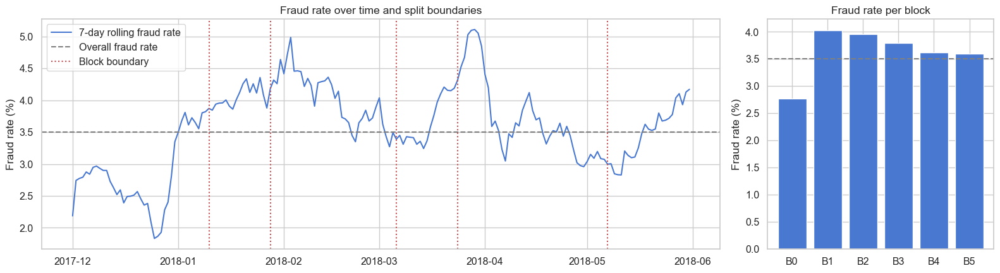

In [54]:
daily = df.groupby(df["TransactionDateTime"].dt.normalize())[LABEL_COL].mean().mul(100)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1]})
axes[0].plot(daily.index, daily.rolling(7, min_periods=1).mean(), color="#4878D0", label="7-day rolling fraud rate")
axes[0].axhline(100 * splits["overall_rate"], color="grey", ls="--", label="Overall fraud rate")
for i, cut in enumerate(splits["cut_dates"]):
    axes[0].axvline(pd.Timestamp(cut), color="#C44E52", ls=":", label="Block boundary" if i == 0 else None)
axes[0].set_title("Fraud rate over time and split boundaries")
axes[0].set_ylabel("Fraud rate (%)")
axes[0].legend()

labels = [f"B{b}" for b in range(len(splits["block_rates"]))]
axes[1].bar(labels, splits["block_rates"], color="#4878D0")
axes[1].axhline(100 * splits["overall_rate"], color="grey", ls="--")
axes[1].set_title("Fraud rate per block")
axes[1].set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.show()

In [55]:
# Compact hand-off for the modelling team: one block id per transaction + the summary table.
# block 0 = initial training data; blocks 1..n_splits = validation blocks; last block = hold-out test
split_assignments = pd.DataFrame({ID_COL: df[ID_COL], "time_block": splits["block"]})
split_assignments.to_csv("split_assignments.csv", index=False)
splits["summary"].to_csv("split_summary.csv", index=False)

# Baseline model: use the last fold (largest training set, most recent validation block)
train_idx, val_idx = cv_splits[-1]
print(f"Baseline split -> train: {len(train_idx):,} rows | validation: {len(val_idx):,} rows | test (hold-out): {len(test_idx):,} rows")

# Hyper-parameter tuning: pass the folds straight to sklearn / Optuna / etc., e.g.
#   GridSearchCV(model, param_grid, cv=cv_splits, scoring="average_precision")
#   cross_val_score(model, X, y, cv=cv_splits)
# Remember: X = df.drop(columns=NON_FEATURE_COLS) after encoding the categorical columns.

Baseline split -> train: 392,750 rows | validation: 127,434 rows | test (hold-out): 70,356 rows
